In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('creditcard.csv')

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Here class 0 - no fraud and 
class 1 - fraud

In [8]:
df.shape

(284807, 31)

It has 284807 row and 31 columns

In [11]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [13]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Class's mean told us about fraud rate it is 0.001727 * 100 = 0.173%

One useful observation: the mean transaction amount is much higher than the median. That suggests the distribution may be right-skewed, with some large transactions pulling the mean upward. We'll verify that with a visualization rather than assume it.

In [15]:
num_col = df.select_dtypes(include = ['number']).columns.tolist()
num_col

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class']

In [16]:
cat_col = df.select_dtypes(include = ['object', 'category']).columns.tolist()
cat_col

[]

Here i can see that this dataset has only numerical columns

In [18]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

WOW good news no null columns 

In [24]:
df.value_counts()

Time      V1          V2          V3         V4         V5         V6         V7          V8          V9         V10        V11        V12        V13        V14        V15        V16        V17        V18        V19        V20        V21         V22        V23        V24        V25        V26        V27        V28        Amount  Class
163152.0  -1.196037    1.585949    2.883976   3.378471   1.511706   3.717077   0.585362   -0.156001    0.122648   4.217934   1.385525  -0.709405  -0.256168  -1.564352   1.693218  -0.785210  -0.228008  -0.412833   0.234834   1.375790  -0.370294    0.524395  -0.355170  -0.869790  -0.133198   0.327804  -0.035702  -0.858197  7.56    0        18
          -1.203617    1.574009    2.889277   3.381404   1.538663   3.698747   0.560211   -0.150911    0.124136   4.220998   1.384569  -0.706897  -0.256274  -1.562583   1.692915  -0.787338  -0.226776  -0.412354   0.234322   1.385597  -0.366727    0.522223  -0.357329  -0.870174  -0.134166   0.327019  -0.042648  -0.85526

In [25]:
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

# Inspect duplicate rows, if any
df[df.duplicated(keep=False)].head(10)

Exact duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


this output not very organized i would like to have more user friendly output and did this show duplicates not sure what this outputs can give me useful

In [27]:
class_counts = df['Class'].value_counts().sort_index()
print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


By this i wanted to understand how many class we have as 1 and 0 

In [29]:
class_percentages = df['Class'].value_counts(normalize=True).sort_index() * 100
print(class_percentages)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


5. Establish a baseline
Calculate the accuracy of a hypothetical model that predicts every transaction as legitimate. Explain why this baseline is deceptive.

How can i do this without having model ?

In [31]:
y_true = df['Class']
y_pred = np.zeros(len(df), dtype = int)

baseline_accuracy = (y_true == y_pred).mean()
print(f"Baseline accuracy: {baseline_accuracy:.4%}")

Baseline accuracy: 99.8273%


In [32]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, zero_division=0))

[[284315      0]
 [   492      0]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    284315
           1       0.00      0.00      0.00       492

    accuracy                           1.00    284807
   macro avg       0.50      0.50      0.50    284807
weighted avg       1.00      1.00      1.00    284807



Accuracy: High, because almost all transactions are legitimate.

Fraud recall: Zero, because the baseline misses every fraudulent transaction.

Fraud precision: Zero, because it never predicts fraud.

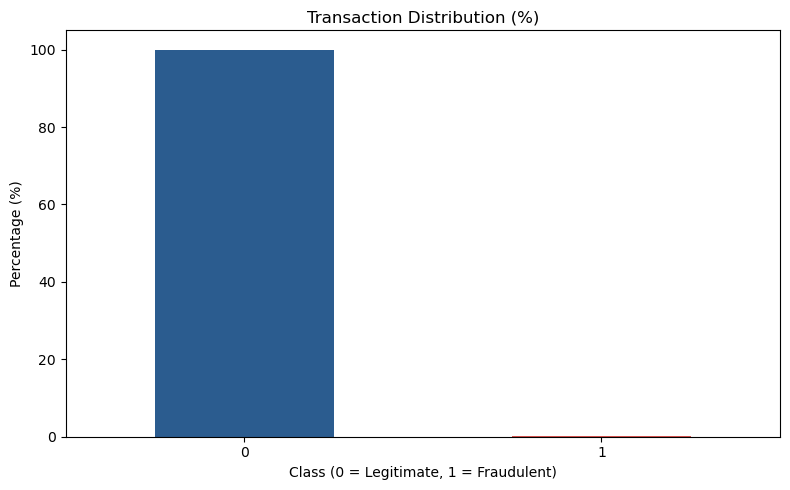

In [34]:
ax = class_percentages.plot(kind='bar', color=['#2b5c8f', '#d9534f'], rot=0, figsize=(8, 5))

plt.title('Transaction Distribution (%)')
plt.ylabel('Percentage (%)')
plt.xlabel('Class (0 = Legitimate, 1 = Fraudulent)')
plt.ylim(0, 105)

plt.tight_layout()
plt.show()

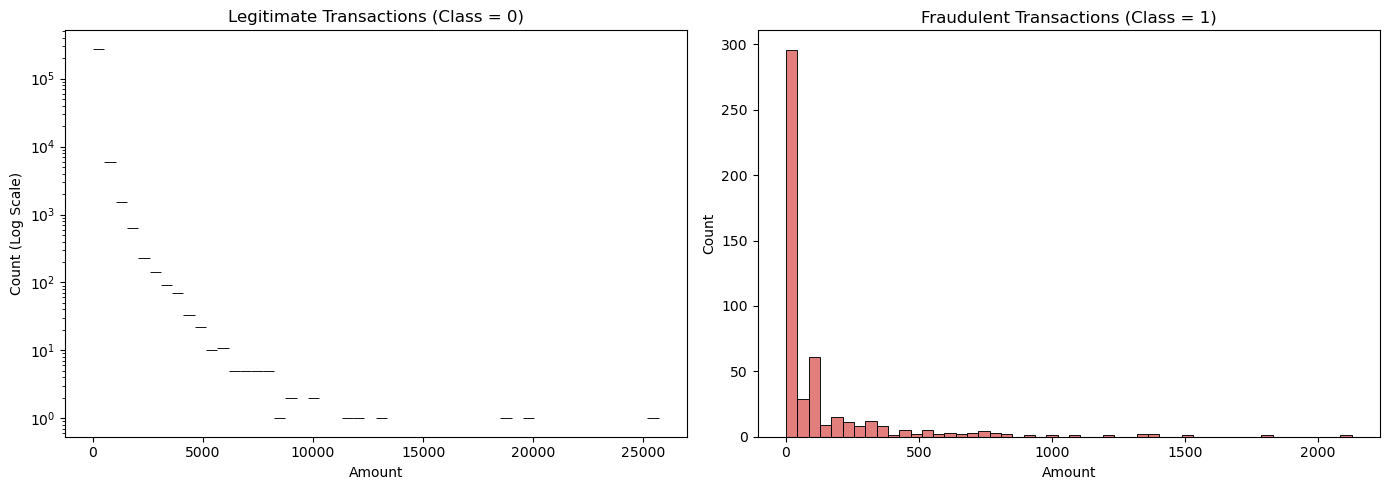

In [35]:
# Set up the figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for Legitimate Transactions (Class = 0)
sns.histplot(
    data=df[df['Class'] == 0], 
    x='Amount', 
    bins=50, 
    ax=axes[0], 
    color='#2b5c8f', 
    log_scale=(False, True)
)
axes[0].set_title('Legitimate Transactions (Class = 0)')
axes[0].set_xlabel('Amount')
axes[0].set_ylabel('Count (Log Scale)')

# Plot for Fraudulent Transactions (Class = 1)
sns.histplot(
    data=df[df['Class'] == 1], 
    x='Amount', 
    bins=50, 
    ax=axes[1], 
    color='#d9534f'
)
axes[1].set_title('Fraudulent Transactions (Class = 1)')
axes[1].set_xlabel('Amount')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

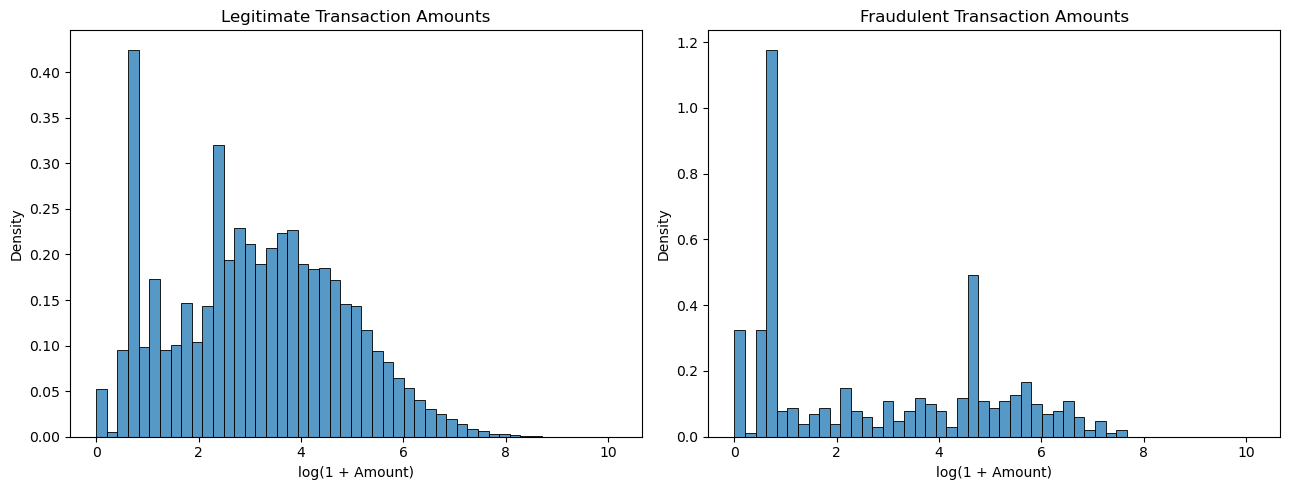

In [36]:
df["log_amount"] = np.log1p(df["Amount"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(
    df["log_amount"].min(),
    df["log_amount"].max(),
    50
)

for class_value, ax, label in [
    (0, axes[0], "Legitimate"),
    (1, axes[1], "Fraudulent")
]:
    subset = df.loc[df["Class"] == class_value]

    sns.histplot(
        data=subset,
        x="log_amount",
        bins=bins,
        stat="density",
        ax=ax
    )

    ax.set_title(f"{label} Transaction Amounts")
    ax.set_xlabel("log(1 + Amount)")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

Both legitimate and fraudulent transaction amounts appear to be right-skewed. Legitimate transactions have a long tail of high-value transactions, while fraudulent transactions are concentrated at lower amounts but also include some high-value transactions. This suggests that transaction amount alone may not be sufficient to identify fraudulent activity.

Limitations: The dataset is highly imbalanced, with substantially fewer fraudulent transactions than legitimate ones. The transaction amount distributions overlap, indicating that amount alone may not reliably distinguish fraud. A logarithmic transformation improves visualization of skewed distributions but compresses large values. Findings about the fraud distribution should also be interpreted cautiously because the number of fraud cases is limited.

In [39]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [40]:
legitimate = df.loc[df["Class"] == 0, "Amount"]

Q1 = legitimate.quantile(0.25)
Q3 = legitimate.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = legitimate[
    (legitimate < lower_bound) | (legitimate > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of legitimate transactions:", len(outliers) / len(legitimate) * 100)

Q1: 5.65
Q3: 77.05
IQR: 71.39999999999999
Lower bound: -101.44999999999999
Upper bound: 184.14999999999998
Number of potential outliers: 31862
Percentage of legitimate transactions: 11.206584246346482


Metric	Result	Meaning

Q1	5.65	25% of legitimate transactions have amounts at or below 5.65

Q3	77.05	75% have amounts at or below 77.05

IQR	71.40	The spread of the middle 50% of amounts

Lower bound	−101.45	Statistical lower outlier threshold

Upper bound	184.15	Statistical upper outlier threshold

Potential outliers	31,862	Legitimate transactions outside the bounds

Outlier percentage	11.21%	Percentage of legitimate transactions flagged by this rule


In [42]:
fraud = df.loc[df["Class"] == 1, "Amount"]

Q1_fraud = fraud.quantile(0.25)
Q3_fraud = fraud.quantile(0.75)
IQR_fraud = Q3_fraud - Q1_fraud

upper_bound_fraud = Q3_fraud + 1.5 * IQR_fraud

fraud_outliers = fraud[fraud > upper_bound_fraud]

print("Fraud Q1:", Q1_fraud)
print("Fraud Q3:", Q3_fraud)
print("Fraud IQR:", IQR_fraud)
print("Fraud upper bound:", upper_bound_fraud)
print("Potential fraud outliers:", len(fraud_outliers))
print("Percentage of fraud transactions:", len(fraud_outliers) / len(fraud) * 100)

Fraud Q1: 1.0
Fraud Q3: 105.89
Fraud IQR: 104.89
Fraud upper bound: 263.225
Potential fraud outliers: 69
Percentage of fraud transactions: 14.02439024390244


Fraudulent transactions have a higher IQR: the middle 50% of fraudulent amounts spans a wider range in this dataset.



The fraudulent outlier percentage is higher: 14.02% versus 11.21%. However, these percentages describe outliers within each class, not the probability that a transaction is fraudulent.



The absolute counts are very different: there are 31,862 legitimate outliers but only 69 fraudulent outliers, partly because the classes have drastically different sample sizes.

In [44]:
from statsmodels.stats.proportion import proportion_confint

fraud_count = int((df["Class"] == 1).sum())
total_count = len(df)

lower, upper = proportion_confint(
    count=fraud_count,
    nobs=total_count,
    alpha=0.05,
    method="wilson"
)

print("Fraud proportion:", fraud_count / total_count)
print("95% confidence interval:", (lower, upper))

Fraud proportion: 0.001727485630620034
95% confidence interval: (0.0015815470496322664, 0.0018868653666960667)


In repeated sampling, if we constructed intervals using this method for many comparable samples, approximately 95% of those intervals would contain the underlying population proportion, under the method's assumptions.

In [ ]:
from statsmodels.stats.proportion import proportion_confint

outlier_count = len(fraud_outliers)
fraud_count = len(fraud)

lower, upper = proportion_confint(
    count=outlier_count,
    nobs=fraud_count,
    alpha=0.05,
    method="wilson"
)

print("Fraud outlier proportion:", outlier_count / fraud_count)
print("95% confidence interval:", (lower, upper))

### Statistical Findings and Uncertainty

The dataset contains 492 fraudulent transactions out of 284,807 transactions, corresponding to an observed fraud proportion of approximately 0.173%. A 95% Wilson confidence interval for the population proportion, under the sampling assumptions, is approximately 0.158%–0.189%.

Using the IQR method separately for each class, 31,862 legitimate transactions (11.21%) and 69 fraudulent transactions (14.02%) were identified as potential upper outliers. The upper thresholds were approximately 184.15 for legitimate transactions and 263.23 for fraudulent transactions.

These results show that statistically extreme transaction amounts occur in both classes. Therefore, an outlier should not automatically be interpreted as fraud. The estimated fraudulent outlier proportion has a relatively wide 95% Wilson confidence interval of approximately 11.23%–17.37%, reflecting uncertainty associated with the smaller fraudulent sample. These descriptive results do not establish predictive performance or causation.

In [ ]:
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.describe())

In [ ]:
df['hour'] = (df["Time"] // 3600) % 24

hourly_transactions = df.groupby('hour').size()

hourly_fraud_transaction = df.groupby('hour')['Class'].sum()

hourly_fraud_rate = df.groupby('hour')['Class'].mean() * 100

print("Transactions per hour:")
print(hourly_transactions)

print("\nFraud cases per hour:")
print(hourly_fraud_transaction)

print("\nFraud rate per hour (%):")
print(hourly_fraud_rate.round(4))

In [ ]:
# Approximate elapsed day
df["day"] = (df["Time"] // 86400).astype(int)

# Hour within each elapsed day
df["hour"] = ((df["Time"] % 86400) // 3600).astype(int)

# Fraud rate by day and hour
fraud_by_day_hour = (
    df.groupby(["day", "hour"])["Class"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

fraud_by_day_hour["fraud_rate_pct"] = (
    fraud_by_day_hour["mean"] * 100
)

print(fraud_by_day_hour.to_string(index=False))

In [ ]:
print(df.groupby("day")["Class"].agg(
    total_transactions="count",
    fraud_cases="sum",
    fraud_rate="mean"
))

In [ ]:
fraud_rate_matrix = fraud_by_day_hour.pivot(
    index="day",
    columns="hour",
    values="fraud_rate_pct"
)

plt.figure(figsize=(16, 3))
sns.heatmap(
    fraud_rate_matrix,
    annot=True,
    fmt=".2f",
    cmap="Reds"
)

plt.title("Fraud Rate by Day and Hour (%)")
plt.xlabel("Hour within elapsed day")
plt.ylabel("Elapsed day")
plt.show()

Hour 2 shows a consistent elevated fraud rate across both elapsed days. However, other elevated periods differ between days, suggesting that the hourly fraud distribution is not fully consistent

In [ ]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

In [ ]:
print(df[["hour", "hour_sin", "hour_cos"]].head(15))

In [ ]:
print(df[["hour", "hour_sin", "hour_cos"]].describe())

In [ ]:
print(
    df.groupby("Class")["Amount"]
      .agg(["count", "mean", "median", "std", "min", "max"])
)

In [ ]:
features_to_check = [
    "Amount",
    "log_amount",
    "Time",
    "day",
    "hour",
    "hour_sin",
    "hour_cos"
]

print(df[features_to_check].isnull().sum())
print(df[features_to_check].describe())

One interesting observation: the mean of day is approximately 0.492, which makes sense because the dataset has slightly more transactions on Day 0 than Day 1.

In [ ]:
X = df.drop(columns = ['Class'])
y = df['Class']

print("Feature shape:", X.shape)
print('Target Shape:', y.shape)

print("\nTarget distribution:")
print(y.value_counts())
print("\nFraud percentage:")
print(y.value_counts(normalize=True) * 100)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nFraud cases in training set:")
print(y_train.value_counts())

print("\nFraud cases in testing set:")
print(y_test.value_counts())

Our dataset is extremely imbalanced: only around 0.17% of transactions are fraudulent.

Without stratification, the training and testing sets might end up with different fraud proportions. stratify=y preserves approximately the same class distribution in both sets.

random_state=42 makes the split reproducible, so we can compare models fairly.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [ ]:
log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter = 1000,
        class_weight = 'balanced',
        random_state = 42
    ))
])

In [ ]:
log_reg_pipeline.fit(X_train,y_train)

In [ ]:
y_pred = log_reg_pipeline.predict(X_test)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

Our model detected 90 out of 98 fraudulent transactions. That's encouraging!

However, it also incorrectly flagged 1,480 legitimate transactions. That's quite a lot.

This illustrates an important trade-off in fraud detection:
- We want high recall: catch as many fraudulent transactions as possible.
- We also want high precision: avoid incorrectly flagging legitimate transactions.

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

- Recall = 0.92: The model catches approximately 92% of fraudulent transactions.
- Precision = 0.06: Only around 6% of transactions flagged as fraud are actually fraudulent.
- F1 = 0.11: The low precision significantly reduces the F1-score.
  
In other words, the model catches most fraud cases, but it generates many false alarms.

In [ ]:
y_prob = log_reg_pipeline.predict_proba(X_test)[:, 1]

print(y_prob[:10])

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.5, 0.7, 0.9]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")

By default, Logistic Regression predicts fraud when its estimated probability reaches 0.5 or higher.



In [ ]:
from sklearn.metrics import confusion_matrix

for threshold in [0.5, 0.7, 0.9]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_test, y_pred_threshold))

By increasing the threshold from 0.5 to 0.9, we eliminated 1,150 false alarms but missed 3 additional fraudulent transactions.

That's a substantial improvement in precision with a relatively small reduction in recall.

In [ ]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_test, y_prob
)

print("Number of thresholds:", len(thresholds))

This calculates precision and recall across many possible thresholds, rather than just 0.5, 0.7 and 0.9.

In [ ]:
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)

print("Best threshold:", thresholds[best_idx])
print("Best precision:", precision_values[best_idx])
print("Best recall:", recall_values[best_idx])
print("Best F1-score:", f1_values[best_idx])

Notice that the threshold is 0.9999999829, extremely close to 1.

This means the model is making very few fraud predictions, but those predictions are much more likely to be correct.

a threshold close to 1 does not mean that many fraud cases will be detected. It means the model requires extremely high confidence before flagging a transaction as fraud.

In [ ]:
best_threshold = thresholds[best_idx]

y_pred_best = (y_prob >= best_threshold).astype(int)

print(confusion_matrix(y_test, y_pred_best))

In [ ]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

In [ ]:
log_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

log_reg_pipeline.fit(X_train_new, y_train_new)

In [ ]:
y_val_prob = log_reg_pipeline.predict_proba(X_val)[:, 1]
print(y_val_prob[:10])

In [ ]:
val_precision, val_recall, val_thresholds = precision_recall_curve(
    y_val, y_val_prob
)

print("Number of thresholds:", len(val_thresholds))

In [ ]:
val_f1 = (
    2 * val_precision[:-1] * val_recall[:-1]
    / (val_precision[:-1] + val_recall[:-1] + 1e-10)
)

best_val_idx = np.argmax(val_f1)

best_val_threshold = val_thresholds[best_val_idx]

print("Best validation threshold:", best_val_threshold)
print("Validation precision:", val_precision[best_val_idx])
print("Validation recall:", val_recall[best_val_idx])
print("Validation F1:", val_f1[best_val_idx])

In [ ]:
y_test_prob = log_reg_pipeline.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= best_val_threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Metric	    Validation	   Test

Precision	 85.1%	       82%

Recall	     72.2%	       80%

F1-score	 0.781	      0.81


The test performance is reasonably close to validation performance. The threshold selected using validation data also generalizes reasonably well to the test set.

In [ ]:
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
import matplotlib.pyplot as plt

ap_score = average_precision_score(y_test, y_test_prob)

print("Average Precision:", ap_score)

PrecisionRecallDisplay.from_predictions(y_test, y_test_prob)
plt.title("Precision-Recall Curve - Logistic Regression")
plt.show()

An AP of 0.7168 indicates that the model can rank fraudulent transactions relatively well, maintaining useful precision across a range of recall levels.

Your model can identify a substantial proportion of fraud cases while keeping false alarms relatively low. But when you try to catch almost every fraud transaction, it starts flagging many legitimate transactions too.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_model.fit(X_train_new, y_train_new)

print("Number of trees:", len(rf_model.estimators_))

In [ ]:
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

print(y_val_prob_rf[:10])
print("Number of predictions:", len(y_val_prob_rf))

Notice the values are mostly 0.000 or very small numbers. That's expected with Random Forest: its predicted probability is based on the proportion of trees voting for fraud.

In [ ]:
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_val,
    y_val_prob_rf
)

print("Number of thresholds:", len(rf_thresholds))

In [ ]:
rf_f1 = (
    2 * rf_precision[:-1] * rf_recall[:-1]
    / (rf_precision[:-1] + rf_recall[:-1] + 1e-10)
)

best_rf_idx = np.argmax(rf_f1)

best_rf_threshold = rf_thresholds[best_rf_idx]

print("Best threshold:", best_rf_threshold)
print("Validation precision:", rf_precision[best_rf_idx])
print("Validation recall:", rf_recall[best_rf_idx])
print("Validation F1:", rf_f1[best_rf_idx])

Why do we use [:-1]? The precision and recall arrays have one more element than the threshold array, so we exclude the final precision and recall values when matching them to thresholds.

Unlike Logistic Regression, Random Forest produces probabilities in increments related to its 200 trees' votes. That's why its threshold is much lower and its probability values are often discrete.

In [ ]:
y_test_prob_rf = rf_model.predict_proba(X_test)[:, 1]

y_test_pred_rf = (
    y_test_prob_rf >= best_rf_threshold
).astype(int)

In [ ]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))

Random Forest:
- Detected 4 additional fraud transactions.
- Reduced false positives from 17 to 7.
- Improved F1-score from 0.81 to 0.88.

In [ ]:
rf_ap = average_precision_score(y_test, y_test_prob_rf)

print("Random Forest Average Precision:", rf_ap)

PrecisionRecallDisplay.from_predictions(y_test, y_test_prob_rf)
plt.title("Precision-Recall Curve - Random Forest")
plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X_train_new.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

In [ ]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    rf_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

Permutation Importance. It gives us a different way to assess feature importance by measuring how much model performance decreases when a feature is randomly shuffled.

In [ ]:
perm_results = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_importance.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

print(perm_results.head(15))

When we randomly shuffle V4, the model's Average Precision decreases by approximately 0.039. This suggests that V4 provides useful information for fraud detection.

These values are AP decreases, not percentages, and they don't need to sum to 1.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

Gradient Boosting: Builds trees sequentially, with each new tree attempting to correct the errors of the previous ensemble.

In [ ]:
gb_model.fit(X_train_new, y_train_new)

In [ ]:
y_val_gb_prob = gb_model.predict_proba(X_val)[:, 1]

print(y_val_gb_prob[:10])
print("Number of predictions:", len(y_val_gb_prob))

In [ ]:
gb_precision, gb_recall, gb_thresholds = precision_recall_curve(
    y_val,
    y_val_gb_prob
)

In [ ]:
gb_f1 = (
    2 * gb_precision[:-1] * gb_recall[:-1]
    / (gb_precision[:-1] + gb_recall[:-1] + 1e-10)
)

best_gb_idx = np.argmax(gb_f1)

best_gb_threshold = gb_thresholds[best_gb_idx]

print("Best threshold:", best_gb_threshold)
print("Validation precision:", gb_precision[best_gb_idx])
print("Validation recall:", gb_recall[best_gb_idx])
print("Validation F1:", gb_f1[best_gb_idx])

In [ ]:
y_test_prob_gb = gb_model.predict_proba(X_test)[:, 1]

y_test_pred_gb = (
    y_test_prob_gb >= best_gb_threshold
).astype(int)

In [ ]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_gb))

Gradient Boosting is sensitive to hyperparameters. For example:
- n_estimators controls the number of boosting stages.
- learning_rate controls how strongly each tree contributes.
- max_depth controls the complexity of individual trees.

We shouldn't conclude that Gradient Boosting is generally inferior based on one configuration.

In [ ]:
gb_ap = average_precision_score(y_test, y_test_prob_gb)

print("Gradient Boosting Average Precision:", gb_ap)

Logistic Regression: A strong baseline, despite its linear assumptions.



Random Forest: Best balance of precision and recall, and the strongest ranking performance.



Gradient Boosting: Underperformed with our initial hyperparameter configuration.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_dist = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5],
    "class_weight": ["balanced_subsample", "balanced"]
}

In [ ]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=8,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [ ]:
rf_search.fit(X_train_new, y_train_new)

In [ ]:
print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation AP:")
print(rf_search.best_score_)

In [ ]:
best_rf_model = rf_search.best_estimator_

In [ ]:
y_val_prob_tuned = best_rf_model.predict_proba(X_val)[:, 1]

In [ ]:
precision_tuned, recall_tuned, thresholds_tuned = precision_recall_curve(
    y_val, y_val_prob_tuned
)

f1_tuned = (
    2 * precision_tuned[:-1] * recall_tuned[:-1]
    / (precision_tuned[:-1] + recall_tuned[:-1] + 1e-10)
)

best_idx_tuned = np.argmax(f1_tuned)

best_threshold_tuned = thresholds_tuned[best_idx_tuned]

print("Best threshold:", best_threshold_tuned)
print("Validation precision:", precision_tuned[best_idx_tuned])
print("Validation recall:", recall_tuned[best_idx_tuned])
print("Validation F1:", f1_tuned[best_idx_tuned])

In [ ]:
y_test_prob_tuned = best_rf_model.predict_proba(X_test)[:, 1]

y_test_pred_tuned = (
    y_test_prob_tuned >= best_threshold_tuned
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_tuned))

print(
    "Test Average Precision:",
    average_precision_score(y_test, y_test_prob_tuned)
)

Hyperparameter tuning did not meaningfully improve the original Random Forest. The tuned model has almost identical performance, with one additional false positive and essentially the same AP.

In [ ]:
tunes_importance = pd.DataFrame({
    "Feature": X_train_new.columns,
    "Importance": best_rf_model.feature_importances_ 
})

tunes_importance = tunes_importance.sort_values(
    by = "Importance",
    ascending = False
)

print(tunes_importance.head(15).to_string(index=False))

In [ ]:
tuned_permutation = permutation_importance(
    best_rf_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

tuned_permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": tuned_permutation.importances_mean,
    "Std": tuned_permutation.importances_std
})

tuned_permutation_df = tuned_permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print(tuned_permutation_df.head(15).to_string(index=False))

Built-in importance measures how much a feature helps trees reduce impurity while they are being constructed.



Permutation importance measures how much the trained model's predictive performance suffers when that feature's values are shuffled.

The rankings and values are remarkably similar. This supports our earlier finding that hyperparameter tuning did not fundamentally change the model's behavior.

### Feature Importance — Tuned Random Forest

Feature importance was evaluated using two approaches:

**1. Built-in feature importance**

V14 was the most important feature (0.1841), followed by V4 (0.1051), V12 (0.0941), V17 (0.0853) and V10 (0.0767).

**2. Permutation importance**

Permutation importance was calculated on the validation set using Average Precision as the scoring metric.

V4 ranked first, followed by V14, V3, V10 and V11. Shuffling V4 reduced Average Precision by approximately 0.0461.

**Conclusion:**

Both methods consistently identified V4, V14, V12, V10 and V11 among the important predictive features. The rankings were also very similar to those of the original Random Forest.

The results suggest that hyperparameter tuning preserved the model's overall feature-importance structure. However, these importance scores do not establish causality or indicate the direction of a feature's relationship with fraud. Since V1–V28 are anonymized PCA components, their real-world meanings cannot be directly interpreted.

In [ ]:
false_negatives_rf = X_test[
    (y_test == 1) & (y_test_pred_rf == 0)
]

false_positives_rf = X_test[
    (y_test == 0) & (y_test_pred_rf == 1)
]

print("Original RF - False Negatives:", len(false_negatives_rf))
print("Original RF - False Positives:", len(false_positives_rf))

In [ ]:
false_negatives_rf["Amount"].describe()

In [ ]:
fraud_test = X_test[y_test == 1]

print("All fraud transactions:")
print(fraud_test["Amount"].describe())

print("\nMissed fraud transactions:")
print(false_negatives_rf["Amount"].describe())

Lower median: Missed fraud transactions have a median amount of 4.14, compared with 10.35 for all fraud. This suggests the model may struggle with some low-value fraud transactions.



Higher mean: Missed fraud has a higher mean (126.42), despite its lower median. This suggests some larger transactions are influencing the average.



Wide variation: The missed cases range from 1 to 635.10, so they aren't limited to one transaction-amount category.

In [ ]:
false_negatives_rf[
    ["V1", "V2", "V3", "V4", "V10", "V12", "V14", "V17", "Amount"]
]

A. The missed fraud cases are quite diverse.

Their amounts range from 1.00 to 635.10. Their PCA values also vary considerably.

This suggests that the model isn't simply missing one specific type of transaction.

B. V14 and V12 deserve attention.

Both were among our most important features:
- V14 had the highest impurity importance.
- V12 was third in impurity importance.
- V14 and V12 also ranked highly in permutation importance.
Some missed cases have very extreme values in these features. For example, row 8972 has V12 = -7.004 and V14 = -6.221.

However, an important feature can still be associated with missed predictions. Feature importance measures overall contribution, not whether every fraud case is detected.

C. Low transaction amounts appear frequently.

Several missed cases have amounts around 1–5. This is consistent with our earlier observation about the lower median, but we need to compare against successfully detected fraud before drawing conclusions.

In [ ]:
detected_fraud = X_test[
    (y_test == 1) & (y_test_pred_rf == 1)
]

comparison = pd.DataFrame({
    "Detected fraud": detected_fraud[
        ["V4", "V12", "V14", "Amount"]
    ].mean(),
    "Missed fraud": false_negatives_rf[
        ["V4", "V12", "V14", "Amount"]
    ].mean()
})

print(comparison)

V4: Detected fraud transactions have a higher average V4 value.

V12 and V14: This is particularly interesting. Both features have much more negative averages among detected fraud transactions.

Since V12 and V14 are important to our Random Forest, this suggests that the model may be better at detecting fraud cases with certain PCA-feature patterns.

Amount: Missed fraud transactions have a higher average amount, but the difference is relatively small compared with the variation in transaction amounts.

Remember: V1–V28 are anonymized PCA components. We cannot assign them real-world meanings such as customer behavior or transaction location.

In [ ]:
comparison_median = pd.DataFrame({
    "Detected fraud": detected_fraud[
        ["V4", "V12", "V14", "Amount"]
    ].median(),

    "Missed fraud": false_negatives_rf[
        ["V4", "V12", "V14", "Amount"]
    ].median()
})

print(comparison_median)

- V4 is generally higher among detected fraud cases.
- V12 and V14 are considerably more negative among detected fraud cases.
- Missed fraud cases have a lower median transaction amount.
This suggests the model detects certain PCA-feature patterns more consistently than others.

In [ ]:
false_positives_rf["Amount"].describe()

In [ ]:
legitimate_test = X_test[y_test == 0]

print("All legitimate transactions:")
print(legitimate_test["Amount"].describe())

print("\nFalse positive transactions:")
print(false_positives_rf["Amount"].describe())

1. Much lower median: False positives have a median amount of just 1.00, compared with 22.00 for legitimate transactions overall.
2. Lower mean: Their average amount is 32.61.
3. No unusually large transactions: All seven false positives are below 90.
This suggests that our model sometimes flags small legitimate transactions as fraud.

In [ ]:
false_positives_rf[
    ["V1", "V2", "V3", "V4", "V10", "V12", "V14", "V17", "Amount"]
]

- V1 and V3: All seven transactions have negative values, several of them extremely negative.
- V4: All seven have positive values, ranging approximately from 0.58 to 6.41.
- V14: All seven have negative values, ranging from approximately -2.54 to -8.57.
- V17: All seven also have negative values.
- Amount: Most are small transactions, although two are 89.99.

In [ ]:
true_negatives_rf = X_test[
    (y_test == 0) & (y_test_pred_rf == 0)
]

# Compare means across all features
fp_comparison = pd.DataFrame({
    "True Negatives": true_negatives_rf.mean(),
    "False Positives": false_positives_rf.mean()
})

fp_comparison["Difference"] = (
    fp_comparison["False Positives"]
    - fp_comparison["True Negatives"]
)

print(
    fp_comparison.reindex(
        fp_comparison["Difference"].abs().sort_values(
            ascending=False
        ).index
    )
)

The false-positive transactions have substantially different average values in several PCA features compared with correctly classified legitimate transactions.

This is consistent with what we observed earlier: the model may be flagging legitimate transactions that have some feature patterns resembling fraud.

In [ ]:
tn_mean = true_negatives_rf.mean()
fp_mean = false_positives_rf.mean()

tn_std = true_negatives_rf.std()
fp_std = false_positives_rf.std()

pooled_std = np.sqrt(
    (tn_std**2 + fp_std**2) / 2
)

standardized_diff = (fp_mean - tn_mean) / pooled_std

fp_analysis = pd.DataFrame({
    "True Negatives Mean": tn_mean,
    "False Positives Mean": fp_mean,
    "Standardized Difference": standardized_diff
})

fp_analysis = fp_analysis.sort_values(
    "Standardized Difference",
    key=abs,
    ascending=False
)

print(fp_analysis)

V12 = -4.34: false positives have considerably lower average V12 values.



V11 = +3.35: false positives have considerably higher average V11 values.



hour_sin = +2.05: false positives have higher average hour_sin values, suggesting a possible time-of-day difference.

One unusual transaction can strongly influence the averages.



The standardized differences may be exaggerated.



We should not claim that these patterns represent all legitimate transactions.

False-positive analysis — Random Forest
- The model produced 7 false positives on the test set.
- Their median transaction amount was 1, compared with 22 for correctly classified legitimate transactions.
- Several PCA components, particularly V12, V17, V11, V16 and V4, showed substantial differences between the groups.
- False positives also occurred earlier in the dataset's recorded time period on average.
- Due to the small number of false positives, these observations are exploratory and cannot establish general patterns.

In [ ]:
false_negatives_tuned = X_test[
    (y_test == 1) & (y_test_pred_tuned == 0)
]

false_positives_tuned = X_test[
    (y_test == 0) & (y_test_pred_tuned == 1)
]

# Compare overlapping errors
common_fp = set(false_positives_rf.index) & set(false_positives_tuned.index)
common_fn = set(false_negatives_rf.index) & set(false_negatives_tuned.index)

print("Original RF false positives:", len(false_positives_rf))
print("Tuned RF false positives:", len(false_positives_tuned))
print("False positives shared:", len(common_fp))

print()

print("Original RF false negatives:", len(false_negatives_rf))
print("Tuned RF false negatives:", len(false_negatives_tuned))
print("False negatives shared:", len(common_fn))

### Error Analysis — Random Forest

Error analysis was performed on the original Random Forest model to understand its false positives and false negatives.

**False negatives (missed fraud):**
- The model missed 16 out of 98 fraudulent transactions.
- Missed transactions showed considerable variation in transaction amounts.
- Their median transaction amount was 4.14, compared with 10.345 across all fraudulent test transactions.
- Several important PCA features, including V4, V12 and V14, had different median values between detected and missed fraud cases.

**False positives (legitimate transactions classified as fraud):**
- The model incorrectly flagged 7 legitimate transactions.
- Their median transaction amount was 1, compared with 22 among correctly classified legitimate transactions.
- Standardized mean differences highlighted substantial differences in several PCA components, particularly V12, V17, V11, V16 and V4.
- These findings are exploratory because the false-positive sample is very small.

**Comparison with the tuned Random Forest:**
- Original model: 7 false positives and 16 false negatives.
- Tuned model: 8 false positives and 16 false negatives.
- Both models shared 6 false positives and all 16 false negatives.

**Conclusion:**

Hyperparameter tuning produced almost identical test performance and did not reduce the number of missed fraudulent transactions. The error analysis suggests that both models struggle with the same fraudulent cases. Further experiments with feature engineering and alternative modeling strategies may help investigate whether these limitations can be reduced.

In [ ]:
original_features = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + ["Amount"]
)

feature_sets = {
    "A - Original": original_features,

    "B - Log Amount": original_features + [
        "log_amount"
    ],

    "C - Time Components": original_features + [
        "day", "hour"
    ],

    "D - Cyclical Time": original_features + [
        "day", "hour_sin", "hour_cos"
    ],

    "E - All Engineered": original_features + [
        "log_amount", "day", "hour",
        "hour_sin", "hour_cos"
    ]
}

In [ ]:
from sklearn.base import clone

experiment_results = []
experiment_models = {}

for name, features in feature_sets.items():

    model = clone(best_rf_model)

    model.fit(
        X_train_new[features],
        y_train_new
    )

    val_prob = model.predict_proba(
        X_val[features]
    )[:, 1]

    ap = average_precision_score(
        y_val,
        val_prob
    )

    experiment_models[name] = model

    experiment_results.append({
        "Experiment": name,
        "Number of Features": len(features),
        "Validation AP": ap
    })

results_df = pd.DataFrame(experiment_results)

print(
    results_df.sort_values(
        by="Validation AP",
        ascending=False
    ).to_string(index=False)
)

In [ ]:
additional_feature_sets = {
    "Original": original_features,

    "Original + day": original_features + [
        "day"
    ],

    "Original + hour": original_features + [
        "hour"
    ],

    "Original + hour_sin/cos": original_features + [
        "hour_sin", "hour_cos"
    ],

    "Original + day + sin/cos": original_features + [
        "day", "hour_sin", "hour_cos"
    ]
}

In [ ]:
additional_results = []

for name, features in additional_feature_sets.items():

    model = clone(best_rf_model)

    model.fit(
        X_train_new[features],
        y_train_new
    )

    val_prob = model.predict_proba(
        X_val[features]
    )[:, 1]

    ap = average_precision_score(
        y_val,
        val_prob
    )

    additional_results.append({
        "Experiment": name,
        "Validation AP": ap
    })

additional_results_df = pd.DataFrame(additional_results)

print(
    additional_results_df.sort_values(
        "Validation AP",
        ascending=False
    ).to_string(index=False)
)

### Feature Engineering Experiments

Several feature configurations were evaluated using the tuned Random Forest model. Average Precision (AP) on the validation set was used for comparison.

**Experiments:**
- Original features: AP = 0.8200
- Original + log_amount: AP = 0.8171
- Original + day + hour: AP = 0.8092
- Original + day + cyclical hour encoding: AP = 0.8264
- Original + all engineered features: AP = 0.8054

Additional experiments were conducted to isolate the contribution of time features.

**Key findings:**
- Adding `day` alone produced a small improvement.
- Adding `hour_sin` and `hour_cos` alone resulted in almost unchanged performance.
- Adding ordinary `hour` decreased Average Precision.
- Combining `day`, `hour_sin` and `hour_cos` achieved the best validation AP of 0.8264.

**Conclusion:**

The combination of elapsed day and cyclical hour encoding provided the most promising feature-engineering result. However, the improvement over the original feature set was relatively small.

The dataset covers approximately 48 hours, so the usefulness of the `day` feature may be specific to this dataset. Further validation on temporally separate data would be necessary to establish generalizability.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

comparison_features = {
    "Original": original_features,

    "Cyclical Time": original_features + [
        "day", "hour_sin", "hour_cos"
    ]
}

comparison_results = []
comparison_models = {}

for name, features in comparison_features.items():

    # Create and train a fresh model
    model = clone(best_rf_model)

    model.fit(
        X_train_new[features],
        y_train_new
    )

    # Predict fraud probabilities on validation data
    val_prob = model.predict_proba(
        X_val[features]
    )[:, 1]

    # Calculate Average Precision
    ap = average_precision_score(y_val, val_prob)

    # Find the best threshold using validation F1
    precision, recall, thresholds = precision_recall_curve(
        y_val, val_prob
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_values)
    best_threshold = thresholds[best_idx]

    # Generate predictions using the selected threshold
    val_pred = (val_prob >= best_threshold).astype(int)

    # Calculate validation metrics
    comparison_results.append({
        "Model": name,
        "Features": len(features),
        "Threshold": best_threshold,
        "AP": ap,
        "Precision": precision_score(y_val, val_pred),
        "Recall": recall_score(y_val, val_pred),
        "F1": f1_score(y_val, val_pred)
    })

    comparison_models[name] = {
        "model": model,
        "features": features,
        "threshold": best_threshold
    }

comparison_df = pd.DataFrame(comparison_results)

print(
    comparison_df.to_string(index=False)
)

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

final_test_results = []

for name, info in comparison_models.items():

    model = info["model"]
    features = info["features"]
    threshold = info["threshold"]

    # Predict probabilities on the untouched test set
    test_prob = model.predict_proba(
        X_test[features]
    )[:, 1]

    # Apply validation-selected threshold
    test_pred = (test_prob >= threshold).astype(int)

    # Calculate metrics
    final_test_results.append({
        "Model": name,
        "AP": average_precision_score(y_test, test_prob),
        "Precision": precision_score(y_test, test_pred),
        "Recall": recall_score(y_test, test_pred),
        "F1": f1_score(y_test, test_pred),
        "Confusion Matrix": confusion_matrix(
            y_test, test_pred
        ).tolist()
    })

final_test_df = pd.DataFrame(final_test_results)

print(final_test_df.to_string(index=False))

### Final Feature Engineering Evaluation

The original Random Forest and the model with additional cyclical time features were evaluated on the untouched test set.

| Metric | Original RF | Cyclical Time RF |
|---|---:|---:|
| Average Precision | 0.8530 | 0.8591 |
| Precision | 0.9011 | 0.8817 |
| Recall | 0.8367 | 0.8367 |
| F1-score | 0.8677 | 0.8586 |
| False Positives | 9 | 11 |
| False Negatives | 16 | 16 |

**Key observations:**

- Cyclical time encoding increased Average Precision from 0.8530 to 0.8591.
- Both models detected 82 out of 98 fraudulent transactions.
- Both models missed the same number of fraudulent transactions (16).
- The cyclical model generated two additional false positives.
- The original model achieved better precision and F1-score despite using fewer features.

**Conclusion:**

Cyclical time encoding provided a small improvement in ranking performance but did not improve the final precision-recall balance at the selected thresholds.

The original 30-feature Random Forest was retained as the preferred model because it achieved better precision and F1-score with a simpler feature set.

The improvement in Average Precision from cyclical encoding is still noteworthy, but further evaluation on temporally independent data would be needed to establish whether this improvement generalizes.

Step 1: checking how fraud cases are distributed over time.

In [ ]:
df_sorted = df.sort_values("Time").copy()

df_sorted["time_group"] = pd.qcut(
    df_sorted["Time"],
    q=5,
    labels=["Group 1", "Group 2", "Group 3", "Group 4", "Group 5"]
)

time_distribution = df_sorted.groupby(
    "time_group", observed=True
)["Class"].agg(
    total_transactions="count",
    fraud_cases="sum",
    fraud_rate="mean"
)

time_distribution["fraud_rate"] *= 100

print(time_distribution)

If the fraud patterns change over time, the model might struggle to recognize fraud in later transactions.

This is called temporal distribution shift: the statistical characteristics of the data change over time.

Next step — Create chronological train, validation and test sets
We'll use:
- Earliest 60% → Training
- Next 20% → Validation
- Latest 20% → Testing

In [69]:
df_temporal = df.sort_values("Time").copy()

train_end = int(len(df_temporal) * 0.60)
val_end = int(len(df_temporal) * 0.80)

train_temporal = df_temporal.iloc[:train_end]
val_temporal = df_temporal.iloc[train_end:val_end]
test_temporal = df_temporal.iloc[val_end:]

X_train_temporal = train_temporal.drop(columns=["Class"])
y_train_temporal = train_temporal["Class"]

X_val_temporal = val_temporal.drop(columns=["Class"])
y_val_temporal = val_temporal["Class"]

X_test_temporal = test_temporal.drop(columns=["Class"])
y_test_temporal = test_temporal["Class"]

for name, y_part in [
    ("Training", y_train_temporal),
    ("Validation", y_val_temporal),
    ("Testing", y_test_temporal)
]:
    print(
        f"{name}: {len(y_part)} transactions | "
        f"{y_part.sum()} fraud cases | "
        f"Fraud rate: {y_part.mean() * 100:.4f}%"
    )

Training: 170884 transactions | 360 fraud cases | Fraud rate: 0.2107%
Validation: 56961 transactions | 57 fraud cases | Fraud rate: 0.1001%
Testing: 56962 transactions | 75 fraud cases | Fraud rate: 0.1317%


In [71]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve
)
import numpy as np

X_train_chrono = X_train_temporal[original_features]
X_val_chrono = X_val_temporal[original_features]

rf_chrono = clone(best_rf_model)

rf_chrono.fit(X_train_chrono, y_train_temporal)

y_val_prob_chrono = rf_chrono.predict_proba(X_val_chrono)[:, 1]

chrono_val_ap = average_precision_score(
    y_val_temporal,
    y_val_prob_chrono
)

precision, recall, thresholds = precision_recall_curve(
    y_val_temporal,
    y_val_prob_chrono
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_chrono_threshold = thresholds[best_idx]

print("Validation Average Precision:", chrono_val_ap)
print("Best threshold:", best_chrono_threshold)
print("Validation precision:", precision[best_idx])
print("Validation recall:", recall[best_idx])
print("Validation F1:", f1_scores[best_idx])

NameError: name 'best_rf_model' is not defined

AP decreased from 0.8200 to 0.7617. This suggests the model has more difficulty ranking fraud cases against legitimate transactions in the later period.



Precision increased to 95.45%. When the model flags a transaction as fraudulent, it is usually correct.



Recall decreased to 73.68%. It misses more actual fraud cases.



F1 remained quite close: 0.832 versus 0.838.

In [74]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    classification_report
)

X_test_chrono = X_test_temporal[original_features]

y_test_prob_chrono = rf_chrono.predict_proba(
    X_test_chrono
)[:, 1]

y_test_pred_chrono = (
    y_test_prob_chrono >= best_chrono_threshold
).astype(int)

print("Test Average Precision:",
      average_precision_score(y_test_temporal, y_test_prob_chrono))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_temporal, y_test_pred_chrono))

print("\nClassification Report:")
print(classification_report(y_test_temporal, y_test_pred_chrono))

Test Average Precision: 0.8130176787657031

Confusion Matrix:
[[56881     6]
 [   18    57]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56887
           1       0.90      0.76      0.83        75

    accuracy                           1.00     56962
   macro avg       0.95      0.88      0.91     56962
weighted avg       1.00      1.00      1.00     56962



The chronological evaluation produced slightly lower Average Precision and recall than the random-split evaluation. This suggests that random splitting may provide a more optimistic estimate of performance for future transactions. However, the limited observation period and differences in class prevalence prevent us from establishing temporal degradation conclusively.

In [76]:
model_artifact = {
    "model": rf_chrono,
    "features": original_features,
    "threshold": best_chrono_threshold,
    "model_name": "Random Forest",
}

joblib.dump(model_artifact, "fraud_rf_chronological.joblib")

print("Model saved successfully!")

Model saved successfully!


In [77]:
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Reproducibility
rng = np.random.default_rng(42)

# Convert to NumPy arrays
y_true = np.asarray(y_test_temporal)
y_prob = np.asarray(y_test_prob_chrono)

# Keep the threshold selected on validation data
threshold = best_chrono_threshold

n_iterations = 2000
n_samples = len(y_true)

# Store bootstrap metrics
bootstrap_results = {
    "Average Precision": [],
    "Precision": [],
    "Recall": [],
    "F1": []
}

for _ in range(n_iterations):

    # Randomly sample test indices with replacement
    indices = rng.choice(
        n_samples,
        size=n_samples,
        replace=True
    )

    # Resampled actual labels and predicted probabilities
    y_true_sample = y_true[indices]
    y_prob_sample = y_prob[indices]

    # Skip samples containing only one class
    if len(np.unique(y_true_sample)) < 2:
        continue

    # Apply our fixed validation threshold
    y_pred_sample = (
        y_prob_sample >= threshold
    ).astype(int)

    # Calculate metrics
    bootstrap_results["Average Precision"].append(
        average_precision_score(
            y_true_sample,
            y_prob_sample
        )
    )

    bootstrap_results["Precision"].append(
        precision_score(
            y_true_sample,
            y_pred_sample,
            zero_division=0
        )
    )

    bootstrap_results["Recall"].append(
        recall_score(
            y_true_sample,
            y_pred_sample,
            zero_division=0
        )
    )

    bootstrap_results["F1"].append(
        f1_score(
            y_true_sample,
            y_pred_sample,
            zero_division=0
        )
    )

# Calculate 95% confidence intervals
for metric, values in bootstrap_results.items():

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)
    mean = np.mean(values)

    print(f"\n{metric}")
    print(f"Bootstrap mean: {mean:.4f}")
    print(f"95% CI: [{lower:.4f}, {upper:.4f}]")


Average Precision
Bootstrap mean: 0.8118
95% CI: [0.7231, 0.8875]

Precision
Bootstrap mean: 0.9057
95% CI: [0.8245, 0.9701]

Recall
Bootstrap mean: 0.7589
95% CI: [0.6620, 0.8451]

F1
Bootstrap mean: 0.8248
95% CI: [0.7520, 0.8859]


In [78]:
import pandas as pd
import numpy as np

# Prepare chronological test results
temporal_results = pd.DataFrame({
    "Time": test_temporal["Time"].values,
    "Actual": y_test_temporal.values,
    "Probability": y_test_prob_chrono,
    "Predicted": y_test_pred_chrono
})

# Divide test transactions into 3 chronological groups
temporal_results["period"] = pd.qcut(
    temporal_results["Time"],
    q=3,
    labels=["Early", "Middle", "Late"]
)

# Add transaction amounts
temporal_results["Amount"] = (
    test_temporal["Amount"].values
)

# Save predictions for future SQL analysis
temporal_results.to_csv(
    "fraud_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

print(temporal_results.groupby(
    "period", observed=True
).agg(
    transactions=("Actual", "count"),
    fraud_cases=("Actual", "sum"),
    detected_fraud=("Predicted", "sum")
))

Predictions saved successfully!
        transactions  fraud_cases  detected_fraud
period                                           
Early          18989           32              25
Middle         18990           31              25
Late           18983           12              13


In [79]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

period_metrics = []

for period, group in temporal_results.groupby("period", observed=True):

    y_true_period = group["Actual"]
    y_pred_period = group["Predicted"]
    y_prob_period = group["Probability"]

    period_metrics.append({
        "Period": period,
        "Transactions": len(group),
        "Fraud Cases": int(y_true_period.sum()),
        "Precision": precision_score(
            y_true_period, y_pred_period, zero_division=0
        ),
        "Recall": recall_score(
            y_true_period, y_pred_period, zero_division=0
        ),
        "F1": f1_score(
            y_true_period, y_pred_period, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_true_period, y_prob_period
        )
    })

period_metrics_df = pd.DataFrame(period_metrics)

print(period_metrics_df.round(4).to_string(index=False))

Period  Transactions  Fraud Cases  Precision  Recall     F1  Average Precision
 Early         18989           32     1.0000  0.7812 0.8772             0.8877
Middle         18990           31     1.0000  0.8065 0.8929             0.8524
  Late         18983           12     0.5385  0.5833 0.5600             0.5694


In [80]:
important_features = [
    "V4", "V14", "V3",
    "V10", "V11", "V12"
]

# Add actual fraud labels and time periods to the feature data
fraud_analysis = temporal_results.copy()

fraud_analysis[important_features] = (
    test_temporal[important_features].values
)

# Keep only actual fraudulent transactions
fraud_analysis = fraud_analysis[
    fraud_analysis["Actual"] == 1
]

# Compare feature distributions across periods
feature_comparison = fraud_analysis.groupby(
    "period", observed=True
)[important_features].median()

print(feature_comparison.round(4))

            V4     V14      V3     V10     V11     V12
period                                                
Early   4.2628 -7.3301 -5.4466 -3.2189  2.9000 -4.1637
Middle  4.2332 -6.1062 -5.3883 -3.9632  2.9444 -3.8055
Late    1.7141 -3.2332 -3.5011 -2.8744  1.2901 -2.6441


In [81]:
feature_period_comparison = (
    temporal_results
    .assign(
        V4=test_temporal["V4"].values,
        V14=test_temporal["V14"].values,
        V11=test_temporal["V11"].values
    )
    .groupby(["period", "Actual"], observed=True)[
        ["V4", "V14", "V11"]
    ]
    .median()
)

print(feature_period_comparison.round(4))

                   V4     V14     V11
period Actual                        
Early  0      -0.3048 -0.0210 -0.3291
       1       4.2628 -7.3301  2.9000
Middle 0      -0.3841 -0.0469 -0.3539
       1       4.2332 -6.1062  2.9444
Late   0      -0.3461 -0.0064 -0.2906
       1       1.7141 -3.2332  1.2901


Chronological evaluation: The model performs somewhat worse on later data than on a random split.



Bootstrap confidence intervals: We quantified uncertainty around the chronological test metrics.



Period-level analysis: Performance drops considerably in the Late portion, alongside changes in important fraud-feature medians.

In [83]:
import pandas as pd

fraud_period_data = temporal_results.copy()

fraud_period_data[["V4", "V14", "V11"]] = (
    test_temporal[["V4", "V14", "V11"]].values
)

fraud_period_data = fraud_period_data[
    fraud_period_data["Actual"] == 1
]

print(
    fraud_period_data.groupby("period", observed=True)
    [["V4", "V14", "V11"]]
    .describe()
    .round(4)
)

          V4                                                           V14  \
       count    mean     std     min     25%     50%     75%     max count   
period                                                                       
Early   32.0  4.3421  2.2553  0.1195  2.6430  4.2628  6.0694  7.7836  32.0   
Middle  31.0  4.2871  2.4747 -0.4577  2.5865  4.2332  6.1811  7.7569  31.0   
Late    12.0  1.8062  1.8662 -0.7555  0.9323  1.7141  2.0783  6.9510  12.0   

                ...                   V11                                  \
          mean  ...     75%     max count    mean     std     min     25%   
period          ...                                                         
Early  -7.5739  ... -4.5815 -0.1421  32.0  2.4974  1.6887 -1.5943  1.7878   
Middle -7.1391  ... -4.3408  0.9850  31.0  2.8131  1.8585 -1.5142  1.7827   
Late   -3.1162  ... -1.7250  0.9843  12.0  1.2532  1.0710 -1.4751  0.9925   

                                
           50%     75%     max  
pe

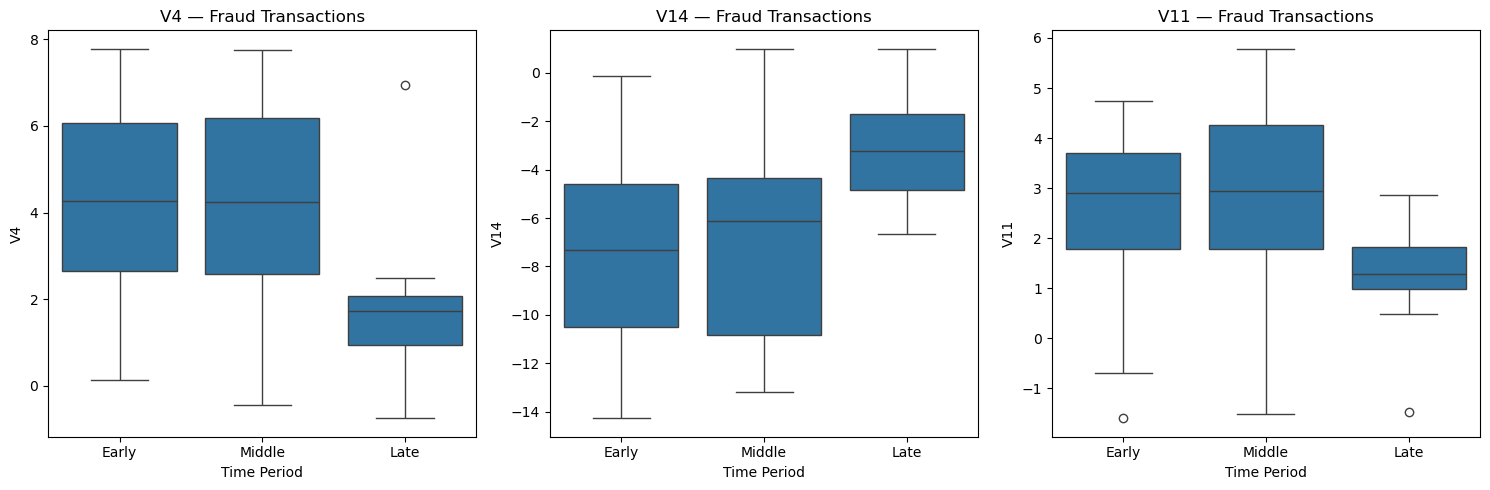

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

features = ["V4", "V14", "V11"]

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=fraud_period_data,
        x="period",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} — Fraud Transactions")
    ax.set_xlabel("Time Period")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

## Robustness Evaluation and Temporal Analysis

### 1. Objective

After selecting the Random Forest classifier as the preferred model, additional experiments were conducted to evaluate the stability and reliability of its performance.

The main objectives were to:

- Evaluate model performance beyond a single random train-test split.
- Examine how the model performs when tested on chronologically later transactions.
- Quantify uncertainty in the evaluation metrics.
- Investigate whether performance changes across different time periods.
- Explore potential changes in fraud transaction patterns over time.

The original 30-feature Random Forest was used for these experiments. This was the preferred model based on its performance in the earlier model and feature-engineering comparisons.

### 2. Cross-Validation During Hyperparameter Tuning

During Random Forest hyperparameter optimization, **3-fold Stratified Cross-Validation** was applied using `StratifiedKFold` with shuffling.

The hyperparameter search used Average Precision (AP) as its scoring metric.

| Evaluation | Result |
|---|---:|
| Cross-validation folds | 3 |
| Hyperparameter configurations evaluated | 8 |
| Total model fits | 24 |
| Best mean CV Average Precision | 0.84797 |

Stratified cross-validation maintains approximately the same fraud-to-legitimate transaction ratio across folds.

This reduces dependence on a single validation split when selecting hyperparameters. However, because the folds were shuffled, this experiment does not evaluate the model's ability to generalize to future transactions.

### 3. Chronological Evaluation

A chronological split was introduced to simulate a more realistic scenario in which a model is trained using historical transactions and evaluated on transactions occurring later.

The dataset was sorted by `Time` and divided into three consecutive subsets:

| Dataset | Transactions | Fraud Cases | Fraud Rate |
|---|---:|---:|---:|
| Training | 170,884 | 360 | 0.2107% |
| Validation | 56,961 | 57 | 0.1001% |
| Testing | 56,962 | 75 | 0.1317% |

The split followed a 60% / 20% / 20% chronological structure.

The model was trained on the earliest 60% of transactions. The next 20% was used for validation and threshold selection, while the final 20% was reserved for testing.

The classification threshold was selected by maximizing F1-score on the chronological validation set.

**Selected threshold: 0.18999**

This threshold was then kept fixed during chronological test evaluation.

#### Random vs. Chronological Test Performance

| Metric | Random Test | Chronological Test |
|---|---:|---:|
| Average Precision | 0.8530 | 0.8130 |
| Precision | 0.9011 | 0.9048 |
| Recall | 0.8367 | 0.7600 |
| F1-score | 0.8677 | 0.8261 |
| False Positives | 9 | 6 |
| False Negatives | 16 | 18 |

The chronological evaluation produced lower Average Precision, recall, and F1-score than the random-split evaluation.

Precision remained similar, indicating that the model continued to identify flagged transactions relatively accurately, but missed a larger proportion of actual fraud cases.

This suggests that the random-split evaluation may provide a somewhat optimistic estimate of performance on later transactions.

However, the two experiments use different training and testing subsets, and their fraud prevalence differs. Therefore, the performance difference cannot be attributed exclusively to temporal changes.

### 4. Bootstrap Confidence Intervals

To investigate the uncertainty of the chronological test results, bootstrap resampling was performed on the chronological test set.

The procedure used 2,000 bootstrap iterations. In each iteration, observations were sampled with replacement, and the evaluation metrics were recalculated using the same classification threshold selected on the chronological validation set.

The 95% percentile confidence intervals were:

| Metric | Test Result | Bootstrap Mean | 95% Confidence Interval |
|---|---:|---:|---:|
| Average Precision | 0.8130 | 0.8118 | [0.7231, 0.8875] |
| Precision | 0.9048 | 0.9057 | [0.8245, 0.9701] |
| Recall | 0.7600 | 0.7589 | [0.6620, 0.8451] |
| F1-score | 0.8261 | 0.8248 | [0.7520, 0.8859] |

The bootstrap means were close to the original test metrics.

The confidence intervals indicate that the estimated performance has some sampling uncertainty, particularly because the chronological test set contains only 75 fraud transactions.

These intervals describe uncertainty arising from resampling the observed test set. They do not guarantee performance on future datasets or account for changes in the underlying transaction distribution.

### 5. Performance Across Chronological Test Periods

To investigate whether model performance remained consistent throughout the chronological test set, it was divided into three approximately equal time periods using transaction timestamps.

The same classification threshold selected on the chronological validation set was applied to all three periods.

| Metric | Early | Middle | Late |
|---|---:|---:|---:|
| Transactions | 18,989 | 18,990 | 18,983 |
| Actual Fraud Cases | 32 | 31 | 12 |
| Precision | 1.0000 | 1.0000 | 0.5385 |
| Recall | 0.7812 | 0.8065 | 0.5833 |
| F1-score | 0.8772 | 0.8929 | 0.5600 |
| Average Precision | 0.8877 | 0.8524 | 0.5694 |

The model performed consistently during the Early and Middle periods, achieving F1-scores of approximately 0.88 and 0.89.

However, performance declined considerably in the Late period:

- Precision decreased to 0.5385.
- Recall decreased to 0.5833.
- F1-score decreased to 0.5600.
- Average Precision decreased to 0.5694.

The Late period contained only 12 actual fraud cases. Consequently, its metrics are particularly sensitive to individual predictions.

The lower fraud prevalence in this period (12 out of 18,983 transactions, approximately 0.0632%) also matters when interpreting Average Precision, since AP is influenced by the prevalence of the positive class.

Nevertheless, the decline across several metrics indicates that model performance was not equally consistent throughout the chronological test set.

### 6. Investigation of Fraud Feature Distributions

To explore possible reasons for the performance decline, the distributions of three important PCA-transformed features were examined among actual fraud transactions across the three periods.

The selected features were:

- **V4:** identified as an important feature by both impurity-based and permutation importance.
- **V14:** consistently ranked among the most important features.
- **V11:** also repeatedly identified as an important predictive feature.

These features were selected because they had consistently appeared among the leading predictors in the previous Random Forest feature-importance analyses.

#### Median Feature Values Among Fraud Transactions

| Feature | Early | Middle | Late |
|---|---:|---:|---:|
| V4 | 4.2628 | 4.2332 | 1.7141 |
| V14 | -7.3301 | -6.1062 | -3.2332 |
| V11 | 2.9000 | 2.9444 | 1.2901 |

The Late period showed noticeable changes in all three features.

- V4 shifted downward.
- V14 became less negative.
- V11 shifted downward.

The full descriptive statistics and boxplots provided additional evidence of these differences.

For example, the middle 50% of V4 values among fraud transactions was:

| Period | 25th Percentile | 75th Percentile |
|---|---:|---:|
| Early | 2.6430 | 6.0694 |
| Middle | 2.5865 | 6.1811 |
| Late | 0.9323 | 2.0783 |

The Late-period V4 distribution was therefore concentrated at substantially lower values.

A similar upward shift was observed in V14, while V11 showed a downward shift and a narrower observed distribution.

#### Comparison with Legitimate Transactions

The median values of these features among legitimate transactions remained relatively stable:

| Feature | Early | Middle | Late |
|---|---:|---:|---:|
| V4 | -0.3048 | -0.3841 | -0.3461 |
| V14 | -0.0210 | -0.0469 | -0.0064 |
| V11 | -0.3291 | -0.3539 | -0.2906 |

This contrast suggests that the observed changes were more pronounced among fraud transactions than among legitimate transactions.

It provides a possible explanation for the reduced ability of the model to recognize fraud in the Late period.

Because V1–V28 are anonymized PCA components, their original real-world meanings cannot be directly interpreted.

### 7. Interpretation and Limitations

The chronological experiments revealed a potential temporal change in fraud transaction patterns.

The model achieved relatively stable performance in the Early and Middle test periods but experienced a noticeable decline in the Late period. At the same time, several important PCA features showed changes in their distributions among fraud transactions.

These observations are consistent with a possible **concept drift** phenomenon, where the relationship between input features and the target variable changes over time.

However, this conclusion must be treated as a hypothesis rather than a confirmed finding.

The investigation has several limitations:

1. **Limited temporal coverage:** The dataset covers approximately 48 hours of transactions, which is insufficient to establish long-term fraud behavior patterns.
2. **Small number of fraud cases:** The Late test period contains only 12 fraud transactions, making its performance estimates less stable.
3. **Anonymized features:** PCA-transformed variables cannot be assigned direct financial or behavioral interpretations.
4. **Single chronological split:** The results may depend on the particular time intervals selected.
5. **Different fraud prevalence:** Fraud rates vary across time periods, affecting metrics such as Average Precision.
6. **No external validation:** The model has not been evaluated on an independent dataset from another period or financial institution.

### 8. Overall Conclusion

The robustness evaluation demonstrated that the Random Forest classifier performs strongly under both random and chronological evaluation, but its performance is not completely consistent across time.

The chronological test achieved an F1-score of 0.8261 and Average Precision of 0.8130. Bootstrap confidence intervals provided an estimate of the uncertainty associated with these results.

Further investigation revealed a substantial performance decline in the Late test period, accompanied by changes in several important fraud-related feature distributions.

These findings highlight the importance of chronological evaluation in fraud detection. A model that performs well on randomly split data may still encounter difficulties when applied to transactions occurring later.

For a real-world fraud detection system, periodic performance monitoring, evaluation on newer transaction data, and potential model retraining would therefore be important considerations.

**Final takeaway:** The Random Forest model demonstrates promising predictive performance, but its ability to generalize across time requires further investigation using larger datasets covering longer periods.

In [86]:
print("temporal_results" in globals())

True


In [87]:
print(temporal_results.head())
print("\nColumns:")
print(temporal_results.columns.tolist())

print("\nShape:")
print(temporal_results.shape)

       Time  Actual  Probability  Predicted period  Amount
0  145248.0       0          0.0          0  Early   50.00
1  145249.0       0          0.0          0  Early   14.95
2  145249.0       0          0.0          0  Early    7.70
3  145249.0       0          0.0          0  Early    6.99
4  145250.0       0          0.0          0  Early  460.71

Columns:
['Time', 'Actual', 'Probability', 'Predicted', 'period', 'Amount']

Shape:
(56962, 6)


In [89]:
import sqlite3

connection = sqlite3.connect("fraud_analysis.db")

temporal_results.to_sql(
    "predictions",
    connection,
    if_exists="replace",
    index=False
)

print("Database and predictions table created successfully!")

Database and predictions table created successfully!


In [91]:
query = """
SELECT *
FROM predictions
LIMIT 5
"""
result = pd.read_sql_query(query, connection)
print(result)

       Time  Actual  Probability  Predicted period  Amount
0  145248.0       0          0.0          0  Early   50.00
1  145249.0       0          0.0          0  Early   14.95
2  145249.0       0          0.0          0  Early    7.70
3  145249.0       0          0.0          0  Early    6.99
4  145250.0       0          0.0          0  Early  460.71


In [92]:
query = """
SELECT 
    CASE
        WHEN Actual = 1 AND Predicted = 1 THEN 'True Positive'
        WHEN Actual = 0 AND Predicted = 0 THEN 'True Negative'
        WHEN Actual = 0 AND Predicted = 1 THEN 'False Positive'
        WHEN Actual = 1 AND Predicted = 0 THEN 'False Negative'
    END AS prediction_type,
    COUNT(*) AS total
FROM predictions
GROUP BY prediction_type
"""
result = pd.read_sql_query(query, connection)

print(result)

  prediction_type  total
0  False Negative     18
1  False Positive      6
2   True Negative  56881
3   True Positive     57


In [93]:
query = """
SELECT
    SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) AS TP,
    SUM(CASE WHEN Actual = 0 AND Predicted = 1 THEN 1 ELSE 0 END) AS FP,
    SUM(CASE WHEN Actual = 1 AND Predicted = 0 THEN 1 ELSE 0 END) AS FN,

    ROUND(
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END), 0),
        4
    ) AS precision,

    ROUND(
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END), 0),
        4
    ) AS recall

FROM predictions;
"""

result = pd.read_sql_query(query, connection)
print(result)

   TP  FP  FN  precision  recall
0  57   6  18     0.9048    0.76


In [94]:
query = """
WITH metrics AS (
    SELECT
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END), 0) AS precision,

        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END), 0) AS recall

    FROM predictions
)

SELECT
    ROUND(precision, 4) AS precision,
    ROUND(recall, 4) AS recall,
    ROUND(
        2.0 * precision * recall /
        NULLIF(precision + recall, 0),
        4
    ) AS f1_score

FROM metrics;
"""

result = pd.read_sql_query(query, connection)
print(result)

   precision  recall  f1_score
0     0.9048    0.76    0.8261


In [95]:
query = """
SELECT
    period,

    COUNT(*) AS total_transactions,

    SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END) AS actual_fraud,

    SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) AS detected_fraud,

    SUM(CASE WHEN Actual = 1 AND Predicted = 0 THEN 1 ELSE 0 END) AS missed_fraud,

    SUM(CASE WHEN Actual = 0 AND Predicted = 1 THEN 1 ELSE 0 END) AS false_alarms

FROM predictions
GROUP BY period
ORDER BY
    CASE period
        WHEN 'Early' THEN 1
        WHEN 'Middle' THEN 2
        WHEN 'Late' THEN 3
    END;
"""

result = pd.read_sql_query(query, connection)
print(result)

   period  total_transactions  actual_fraud  detected_fraud  missed_fraud  \
0   Early               18989            32              25             7   
1  Middle               18990            31              25             6   
2    Late               18983            12               7             5   

   false_alarms  
0             0  
1             0  
2             6  


In [96]:
query = """
SELECT
    period,

    ROUND(
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END), 0),
        4
    ) AS precision,

    ROUND(
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END), 0),
        4
    ) AS recall,

    ROUND(
        2.0 *
        SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(
            SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END) +
            SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END),
            0
        ),
        4
    ) AS f1_score

FROM predictions
GROUP BY period
ORDER BY
    CASE period
        WHEN 'Early' THEN 1
        WHEN 'Middle' THEN 2
        WHEN 'Late' THEN 3
    END;
"""

result = pd.read_sql_query(query, connection)
print(result)

   period  precision  recall  f1_score
0   Early     1.0000  0.7813    0.8772
1  Middle     1.0000  0.8065    0.8929
2    Late     0.5385  0.5833    0.5600


In [97]:
query = """
SELECT
    CASE
        WHEN Actual = 1 AND Predicted = 0 THEN 'False Negative'
        WHEN Actual = 0 AND Predicted = 1 THEN 'False Positive'
        WHEN Actual = 1 AND Predicted = 1 THEN 'True Positive'
        ELSE 'True Negative'
    END AS prediction_type,

    COUNT(*) AS transaction_count,

    ROUND(AVG(Amount), 2) AS average_amount,

    ROUND(MIN(Amount), 2) AS minimum_amount,

    ROUND(MAX(Amount), 2) AS maximum_amount

FROM predictions

WHERE Actual = 1 AND Predicted = 0
   OR Actual = 0 AND Predicted = 1
   OR Actual = 1 AND Predicted = 1

GROUP BY prediction_type
ORDER BY transaction_count DESC;
"""

result = pd.read_sql_query(query, connection)
print(result)

  prediction_type  transaction_count  average_amount  minimum_amount  \
0   True Positive                 57           89.32            0.00   
1  False Negative                 18          146.57            0.00   
2  False Positive                  6            1.42            0.77   

   maximum_amount  
0         1504.93  
1         1096.99  
2            2.00  


In [98]:
query = """
SELECT
    period,
    COUNT(*) AS false_positive_count,
    ROUND(AVG(Amount), 2) AS average_amount,
    ROUND(MIN(Amount), 2) AS minimum_amount,
    ROUND(MAX(Amount), 2) AS maximum_amount

FROM predictions

WHERE Actual = 0 AND Predicted = 1

GROUP BY period
ORDER BY
    CASE period
        WHEN 'Early' THEN 1
        WHEN 'Middle' THEN 2
        WHEN 'Late' THEN 3
    END;
"""

result = pd.read_sql_query(query, connection)
print(result)

  period  false_positive_count  average_amount  minimum_amount  maximum_amount
0   Late                     6            1.42            0.77             2.0


In [99]:
query = """
SELECT
    period,

    CASE
        WHEN Predicted = 1 THEN 'Detected Fraud'
        ELSE 'Missed Fraud'
    END AS fraud_status,

    COUNT(*) AS transaction_count,

    ROUND(AVG(Amount), 2) AS average_amount,

    ROUND(AVG(Probability), 4) AS average_probability

FROM predictions

WHERE Actual = 1

GROUP BY period, fraud_status

ORDER BY
    CASE period
        WHEN 'Early' THEN 1
        WHEN 'Middle' THEN 2
        WHEN 'Late' THEN 3
    END,
    fraud_status;
"""

result = pd.read_sql_query(query, connection)
print(result)

   period    fraud_status  transaction_count  average_amount  \
0   Early  Detected Fraud                 25           54.29   
1   Early    Missed Fraud                  7           89.47   
2  Middle  Detected Fraud                 25          103.65   
3  Middle    Missed Fraud                  6          217.15   
4    Late  Detected Fraud                  7          163.23   
5    Late    Missed Fraud                  5          141.82   

   average_probability  
0               0.4760  
1               0.0471  
2               0.4828  
3               0.0142  
4               0.4157  
5               0.0050  


In [100]:
query = """
SELECT
    CASE
        WHEN Amount < 10 THEN 'Under $10'
        WHEN Amount < 100 THEN '$10-$100'
        WHEN Amount < 500 THEN '$100-$500'
        ELSE 'Above $500'
    END AS amount_range,

    COUNT(*) AS actual_fraud,

    SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END) AS detected_fraud,

    SUM(CASE WHEN Predicted = 0 THEN 1 ELSE 0 END) AS missed_fraud,

    ROUND(
        1.0 * SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(COUNT(*), 0),
        4
    ) AS recall

FROM predictions

WHERE Actual = 1

GROUP BY amount_range

ORDER BY
    CASE amount_range
        WHEN 'Under $10' THEN 1
        WHEN '$10-$100' THEN 2
        WHEN '$100-$500' THEN 3
        WHEN 'Above $500' THEN 4
    END;
"""

result = pd.read_sql_query(query, connection)
print(result)

  amount_range  actual_fraud  detected_fraud  missed_fraud  recall
0    Under $10            45              36             9  0.8000
1     $10-$100            15              11             4  0.7333
2    $100-$500            11               8             3  0.7273
3   Above $500             4               2             2  0.5000


In [101]:
query = """
SELECT
    CASE
        WHEN Amount < 10 THEN 'Under $10'
        WHEN Amount < 100 THEN '$10-$100'
        WHEN Amount < 500 THEN '$100-$500'
        ELSE 'Above $500'
    END AS amount_range,

    COUNT(*) AS total_transactions,

    SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END) AS actual_fraud,

    SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) AS TP,

    SUM(CASE WHEN Actual = 0 AND Predicted = 1 THEN 1 ELSE 0 END) AS FP,

    SUM(CASE WHEN Actual = 1 AND Predicted = 0 THEN 1 ELSE 0 END) AS FN,

    ROUND(
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Predicted = 1 THEN 1 ELSE 0 END), 0),
        4
    ) AS precision,

    ROUND(
        1.0 * SUM(CASE WHEN Actual = 1 AND Predicted = 1 THEN 1 ELSE 0 END) /
        NULLIF(SUM(CASE WHEN Actual = 1 THEN 1 ELSE 0 END), 0),
        4
    ) AS recall

FROM predictions

GROUP BY amount_range

ORDER BY
    CASE amount_range
        WHEN 'Under $10' THEN 1
        WHEN '$10-$100' THEN 2
        WHEN '$100-$500' THEN 3
        WHEN 'Above $500' THEN 4
    END;
"""

result = pd.read_sql_query(query, connection)
print(result)

  amount_range  total_transactions  actual_fraud  TP  FP  FN  precision  \
0    Under $10               21786            45  36   6   9     0.8571   
1     $10-$100               25081            15  11   0   4     1.0000   
2    $100-$500                8480            11   8   0   3     1.0000   
3   Above $500                1615             4   2   0   2     1.0000   

   recall  
0  0.8000  
1  0.7333  
2  0.7273  
3  0.5000  


## SQL-Based Prediction Analysis

### 1. Database Integration
Integrated SQLite into the fraud detection project to store and analyze the chronological Random Forest model's predictions.

- Created a SQLite database (`fraud_analysis.db`).
- Stored 56,962 test predictions in a `predictions` table.
- Used Python and Pandas to transfer prediction results into SQLite.

### 2. Model Performance Analysis
Used SQL conditional aggregation (`CASE WHEN`, `SUM`, `COUNT`) to calculate the confusion matrix and classification metrics.

| Metric | Result |
|---|---:|
| True Positives | 57 |
| True Negatives | 56,881 |
| False Positives | 6 |
| False Negatives | 18 |
| Precision | 90.48% |
| Recall | 76.00% |
| F1-score | 82.61% |

SQL calculations matched the original Python evaluation results.

### 3. Temporal Performance Analysis
Compared model performance across three chronological test periods.

| Period | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Early | 100% | 78.13% | 87.72% |
| Middle | 100% | 80.65% | 89.29% |
| Late | 53.85% | 58.33% | 56.00% |

**Observation:** Model performance declined considerably in the Late period. All six false positives occurred during this period. This may indicate changing fraud patterns, although the small number of fraud cases limits the strength of this conclusion.

### 4. Transaction Amount Analysis
Investigated false positives, false negatives, and fraud detection performance across transaction amount ranges.

Key findings:
- All six false positives involved transactions below 10, with amounts ranging from 0.77 to 2.00 dpllars.
- Missed fraud transactions had a higher average amount (146.57) than detected fraud transactions (89.32) dollars.
- Fraud recall decreased from 80% for transactions under 10 to 50% for transactions above 500 dollars.
- The above-$500 category contained only four fraud cases, so its recall estimate is highly uncertain.

### 5. Conclusion
SQL provided an additional way to investigate model predictions beyond standard Python evaluation metrics. It helped identify temporal performance differences, patterns in false positives and false negatives, and variations in fraud detection across transaction amount ranges.

These findings suggest potential temporal changes in fraud patterns and differences in detection performance across transaction amounts. Further evaluation is needed before drawing definitive conclusions.

In [103]:
print("Training shape:", X_train_temporal.shape)

print("\nTraining class distribution:")
print(y_train_temporal.value_counts())

print("\nFraud percentage:")
print(y_train_temporal.value_counts(normalize=True) * 100)

Training shape: (170884, 31)

Training class distribution:
Class
0    170524
1       360
Name: count, dtype: int64

Fraud percentage:
Class
0    99.789331
1     0.210669
Name: proportion, dtype: float64


474 legitimate transactions for every fraud case. This is a severe class imbalance.

Random Undersampling. It reduces the majority class by randomly removing legitimate transactions while keeping all 360 fraud cases.

In [106]:
from imblearn.under_sampling import RandomUnderSampler

# Select the same 30 features used by our baseline model
X_train_rus = X_train_temporal[original_features]

# Keep all fraud cases, reduce legitimate cases
rus = RandomUnderSampler(
    sampling_strategy=0.1,
    random_state=42
)

X_train_resampled, y_train_resampled = rus.fit_resample(
    X_train_rus,
    y_train_temporal
)

print("Before undersampling:")
print(y_train_temporal.value_counts())

print("\nAfter undersampling:")
print(y_train_resampled.value_counts())

print("\nNew training shape:", X_train_resampled.shape)

Before undersampling:
Class
0    170524
1       360
Name: count, dtype: int64

After undersampling:
Class
0    3600
1     360
Name: count, dtype: int64

New training shape: (3960, 30)


In [107]:
from sklearn.base import clone

rf_rus = clone(rf_chrono)
rf_rus.set_params(class_weight=None)

rf_rus.fit(X_train_resampled, y_train_resampled)

print("Random Forest trained with Random Undersampling!")

Random Forest trained with Random Undersampling!


In [108]:
from sklearn.metrics import average_precision_score

# Predict fraud probabilities on the original validation set
y_val_prob_rus = rf_rus.predict_proba(
    X_val_temporal[original_features]
)[:, 1]

# Calculate Average Precision
ap_rus = average_precision_score(
    y_val_temporal,
    y_val_prob_rus
)

print("Random Undersampling Validation AP:", ap_rus)
print("Class-weighted baseline Validation AP:",
      average_precision_score(y_val_temporal, y_val_prob_chrono))

Random Undersampling Validation AP: 0.7532222562808084


NameError: name 'y_val_prob_chrono' is not defined

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

rus_precision, rus_recall, rus_thresholds = precision_recall_curve(
    y_val_temporal,
    y_val_prob_rus
)

rus_f1 = (
    2 * rus_precision[:-1] * rus_recall[:-1]
    / (rus_precision[:-1] + rus_recall[:-1] + 1e-10)
)

best_rus_idx = np.argmax(rus_f1)

best_rus_threshold = rus_thresholds[best_rus_idx]

print("Best threshold:", best_rus_threshold)
print("Validation Precision:", rus_precision[best_rus_idx])
print("Validation Recall:", rus_recall[best_rus_idx])
print("Validation F1:", rus_f1[best_rus_idx])

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities
y_test_prob_rus = rf_rus.predict_proba(
    X_test_temporal[original_features]
)[:, 1]

# Apply the threshold selected on validation
y_test_pred_rus = (
    y_test_prob_rus >= best_rus_threshold
).astype(int)

# Evaluate
print("Test AP:", average_precision_score(
    y_test_temporal, y_test_prob_rus
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_temporal, y_test_pred_rus))

print("\nClassification Report:")
print(classification_report(y_test_temporal, y_test_pred_rus))


SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic fraud examples based on existing fraud cases and their nearest neighbors. Instead of removing legitimate transactions, it increases the number of minority-class examples.

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy=0.1,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_temporal[original_features],
    y_train_temporal
)

print("Before SMOTE:")
print(y_train_temporal.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nNew training shape:", X_train_smote.shape)

In [ ]:
from sklearn.base import clone

rf_smote = clone(rf_chrono)
rf_smote.set_params(class_weight=None)

rf_smote.fit(X_train_smote, y_train_smote)

print("Random Forest trained with SMOTE!")

In [ ]:
from sklearn.metrics import average_precision_score

y_val_prob_smote = rf_smote.predict_proba(
    X_val_temporal[original_features]
)[:, 1]

ap_smote = average_precision_score(
    y_val_temporal,
    y_val_prob_smote
)

print("SMOTE Validation AP:", ap_smote)
print("Class-weighted baseline AP:", 
      average_precision_score(y_val_temporal, y_val_prob_chrono))
print("Undersampling AP:", ap_rus)

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

smote_precision, smote_recall, smote_thresholds = precision_recall_curve(
    y_val_temporal,
    y_val_prob_smote
)

smote_f1 = (
    2 * smote_precision[:-1] * smote_recall[:-1]
    / (smote_precision[:-1] + smote_recall[:-1] + 1e-10)
)

best_smote_idx = np.argmax(smote_f1)

best_smote_threshold = smote_thresholds[best_smote_idx]

print("Best threshold:", best_smote_threshold)
print("Validation Precision:", smote_precision[best_smote_idx])
print("Validation Recall:", smote_recall[best_smote_idx])
print("Validation F1:", smote_f1[best_smote_idx])

In [ ]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_test_prob_smote = rf_smote.predict_proba(
    X_test_temporal[original_features]
)[:, 1]

y_test_pred_smote = (
    y_test_prob_smote >= best_smote_threshold
).astype(int)

print("Test AP:", average_precision_score(
    y_test_temporal, y_test_prob_smote
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_temporal, y_test_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test_temporal, y_test_pred_smote))

For this particular dataset and chronological split, class weighting remains our preferred method if we prioritize overall ranking quality and F1.

However, SMOTE is worth documenting because it achieved slightly higher fraud recall. That trade-off is important in real fraud detection, where missing a fraudulent transaction can be costly.

One important limitation: we tested one sampling ratio (1:10) for each method. Different ratios might produce different results, so we shouldn't claim these techniques are inherently inferior.

## Class Imbalance Handling Experiments

### Objective

The dataset contains a severe class imbalance, with fraudulent transactions representing approximately 0.17% of all transactions. To investigate how different imbalance-handling techniques affect fraud detection, three approaches were compared using the same Random Forest configuration.

### Experimental Setup

All experiments used:
- The same 30 original features.
- The same chronological 60/20/20 training, validation, and test split.
- The same Random Forest hyperparameters.
- Validation data for threshold selection.
- An untouched test set for final evaluation.

Three approaches were evaluated:

1. **Class Weighting:** Used `class_weight="balanced_subsample"` to assign greater importance to fraudulent transactions during training.
2. **Random Undersampling:** Reduced the majority class to achieve a 1:10 minority-to-majority ratio, retaining all original fraud cases.
3. **SMOTE:** Generated synthetic minority-class examples to achieve the same 1:10 ratio while preserving all legitimate transactions.

For the undersampling and SMOTE experiments, class weighting was disabled to avoid combining multiple imbalance-handling techniques.

### Test Results

| Metric | Class Weighting | Undersampling | SMOTE |
|---|---:|---:|---:|
| Average Precision | **0.8130** | 0.7939 | 0.8116 |
| Precision | **0.9048** | 0.8438 | 0.8406 |
| Recall | 0.7600 | 0.7200 | **0.7733** |
| F1-score | **0.8261** | 0.7770 | 0.8056 |
| False Positives | **6** | 10 | 11 |
| False Negatives | 18 | 21 | **17** |

### Observations

- **Class Weighting** achieved the highest Average Precision, precision, and F1-score, providing the strongest overall performance in this experiment.
- **Random Undersampling** performed worst among the three approaches. Removing a large portion of legitimate transactions may have resulted in losing useful information about the majority class.
- **SMOTE** achieved the highest recall, detecting 58 out of 75 fraudulent transactions. However, it also generated more false positives than class weighting.

### Conclusion

Class weighting was retained as the preferred imbalance-handling approach for the final Random Forest model, based on its overall test performance and lower number of false positives.

SMOTE demonstrated a useful alternative when prioritizing fraud detection recall, while undersampling showed the potential drawbacks of discarding majority-class information.

These findings are specific to the selected chronological split and sampling ratio. Further experiments with different sampling ratios and additional time periods would be necessary to establish whether the observed differences generalize.

In [109]:
required_variables = [
    "X_train_temporal",
    "X_val_temporal",
    "X_test_temporal",
    "y_train_temporal",
    "y_val_temporal",
    "y_test_temporal",
    "original_features",
    "rf_chrono",
    "best_chrono_threshold"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")

X_train_temporal: True
X_val_temporal: True
X_test_temporal: True
y_train_temporal: True
y_val_temporal: True
y_test_temporal: True
original_features: True
rf_chrono: True
best_chrono_threshold: True


In [111]:
from pathlib import Path

for file in Path(".").iterdir():
    if file.suffix.lower() in [".csv", ".joblib", ".ipynb", ".db"]:
        print(file.name)

 Naive Bayes Classifier.ipynb
01_data_investigation.ipynb
01_Iris_Decision_Tree_Classification.ipynb.ipynb
02_Titanic_Feature_Engineering_and_Encoding.ipynb
02_Titanic_Logistic_Regression_Model.ipynb
1000_Companies.csv
2019-05-31-data.csv
adult.csv
BFS and DFS.ipynb
CNN(Convolution Neural Network).ipynb
Confusion Matrix.ipynb
covid-19.csv
creditcard.csv
Cross Validation.ipynb
data.csv
data1.csv
data2.csv
data3.csv
DataCleaningLess.ipynb
Decision Tree.ipynb
Decision_Tree_ Dataset.csv
diabetes.csv
dog.csv
dog_data_short.csv
Email Spam Detection.ipynb
ExamPrep.ipynb
fraud_analysis.db
fraud_predictions.csv
fraud_rf_chronological.joblib
Google_Stock_Price_Test.csv
Google_Stock_Price_Train.csv
gpu_performance_pipeline.ipynb
Hate Speech Detection.ipynb
heart.csv
KNN.ipynb
K_Means.ipynb
Lab12.ipynb
LinearRegression.ipynb
Logistic Regression.ipynb
LSTM(Long Short-Term Memory).ipynb
mail_data.csv
Matplotlib.ipynb
MinMax.ipynb
NumpyLess.ipynb
Overfitting Underfitting.ipynb
PandasLess.ipynb
Pandas

In [113]:
import joblib
import pandas as pd
import numpy as np

# Load saved model artifact
model_artifact = joblib.load("fraud_rf_chronological.joblib")

rf_chrono = model_artifact["model"]
original_features = model_artifact["features"]
best_chrono_threshold = model_artifact["threshold"]

print("Model:", model_artifact["model_name"])
print("Features:", len(original_features))
print("Threshold:", best_chrono_threshold)
print("Model loaded successfully!")

Model: Random Forest
Features: 30
Threshold: 0.18998780601728282
Model loaded successfully!


In [115]:
import sklearn
import inspect
from sklearn.neural_network import MLPClassifier

print("Scikit-learn version:", sklearn.__version__)
print("MLPClassifier.fit signature:")
print(inspect.signature(MLPClassifier.fit))

Scikit-learn version: 1.5.1
MLPClassifier.fit signature:
(self, X, y)


In [117]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Scale features: fit only on training data
scaler_mlp = StandardScaler()

X_train_scaled = scaler_mlp.fit_transform(X_train_temporal)
X_val_scaled = scaler_mlp.transform(X_val_temporal)
X_test_scaled = scaler_mlp.transform(X_test_temporal)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)

print("\nOriginal training distribution:")
print(y_train_temporal.value_counts())

Training shape: (170884, 31)
Validation shape: (56961, 31)
Test shape: (56962, 31)

Original training distribution:
Class
0    170524
1       360
Name: count, dtype: int64


In [119]:
print("Current MLP features:", X_train_temporal.shape[1])
print("Original RF features:", len(original_features))

print("\nCurrent columns:")
print(X_train_temporal.columns.tolist())

print("\nMissing original features:")
print(set(original_features) - set(X_train_temporal.columns))

print("\nExtra features:")
print(set(X_train_temporal.columns) - set(original_features))

Current MLP features: 31
Original RF features: 30

Current columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'log_amount']

Missing original features:
set()

Extra features:
{'log_amount'}


In [121]:
# Keep exactly the same 30 features as Random Forest
X_train_mlp = X_train_temporal[original_features]
X_val_mlp = X_val_temporal[original_features]
X_test_mlp = X_test_temporal[original_features]

# Fit scaler only on training data
scaler_mlp = StandardScaler()

X_train_scaled = scaler_mlp.fit_transform(X_train_mlp)
X_val_scaled = scaler_mlp.transform(X_val_mlp)
X_test_scaled = scaler_mlp.transform(X_test_mlp)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Training: (170884, 30)
Validation: (56961, 30)
Test: (56962, 30)


In [123]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(
    sampling_strategy=0.1,
    random_state=42
)

X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train_scaled,
    y_train_temporal
)

print("Before oversampling:")
print(y_train_temporal.value_counts())

print("\nAfter oversampling:")
print(y_train_resampled.value_counts())

print("\nNew training shape:", X_train_resampled.shape)

Before oversampling:
Class
0    170524
1       360
Name: count, dtype: int64

After oversampling:
Class
0    170524
1     17052
Name: count, dtype: int64

New training shape: (187576, 30)


In [125]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=10,
    random_state=42,
    verbose=True
)

mlp.fit(X_train_resampled, y_train_resampled)

print("\nTraining completed!")
print("Iterations:", mlp.n_iter_)
print("Best validation score:", mlp.best_validation_score_)

Iteration 1, loss = 0.06257011
Validation score: 0.991861
Iteration 2, loss = 0.01885471
Validation score: 0.996588
Iteration 3, loss = 0.00974709
Validation score: 0.999005
Iteration 4, loss = 0.00585070
Validation score: 0.999111
Iteration 5, loss = 0.00378047
Validation score: 0.999254
Iteration 6, loss = 0.00258052
Validation score: 0.999396
Iteration 7, loss = 0.00234961
Validation score: 0.999325
Iteration 8, loss = 0.00197162
Validation score: 0.999467
Iteration 9, loss = 0.00158186
Validation score: 0.999502
Iteration 10, loss = 0.00114436
Validation score: 0.999574
Iteration 11, loss = 0.00172857
Validation score: 0.999467
Iteration 12, loss = 0.00118039
Validation score: 0.999502
Iteration 13, loss = 0.00071599
Validation score: 0.999538
Iteration 14, loss = 0.00126388
Validation score: 0.999645
Iteration 15, loss = 0.00090227
Validation score: 0.999751
Iteration 16, loss = 0.00068456
Validation score: 0.999680
Iteration 17, loss = 0.00066934
Validation score: 0.999751
Iterat

In [127]:
from sklearn.metrics import average_precision_score

# Predict fraud probabilities on the untouched validation set
y_val_mlp_proba = mlp.predict_proba(X_val_scaled)[:, 1]

# Calculate Average Precision
mlp_val_ap = average_precision_score(
    y_val_temporal,
    y_val_mlp_proba
)

print("MLP Validation Average Precision:", mlp_val_ap)

MLP Validation Average Precision: 0.7235468506717098


In [129]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val_temporal,
    y_val_mlp_proba
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_mlp_idx = np.argmax(f1_scores)
best_mlp_threshold = thresholds[best_mlp_idx]

print("Best MLP threshold:", best_mlp_threshold)
print("Validation Precision:", precision[best_mlp_idx])
print("Validation Recall:", recall[best_mlp_idx])
print("Validation F1:", f1_scores[best_mlp_idx])

Best MLP threshold: 0.9814864972760963
Validation Precision: 0.8695652173913043
Validation Recall: 0.7017543859649122
Validation F1: 0.7766990290767839


In [131]:
# Predict probabilities on the untouched chronological test set
y_test_mlp_proba = mlp.predict_proba(X_test_scaled)[:, 1]

# Apply the threshold selected on validation data
y_test_mlp_pred = (
    y_test_mlp_proba >= best_mlp_threshold
).astype(int)

# Evaluate
mlp_test_ap = average_precision_score(
    y_test_temporal,
    y_test_mlp_proba
)

mlp_test_precision = precision_score(
    y_test_temporal, y_test_mlp_pred
)

mlp_test_recall = recall_score(
    y_test_temporal, y_test_mlp_pred
)

mlp_test_f1 = f1_score(
    y_test_temporal, y_test_mlp_pred
)

mlp_test_cm = confusion_matrix(
    y_test_temporal, y_test_mlp_pred
)

print("MLP TEST RESULTS")
print("-------------------------")
print(f"Average Precision: {mlp_test_ap:.4f}")
print(f"Precision:         {mlp_test_precision:.4f}")
print(f"Recall:            {mlp_test_recall:.4f}")
print(f"F1-score:          {mlp_test_f1:.4f}")
print("\nConfusion Matrix:")
print(mlp_test_cm)

MLP TEST RESULTS
-------------------------
Average Precision: 0.7820
Precision:         0.9608
Recall:            0.6533
F1-score:          0.7778

Confusion Matrix:
[[56885     2]
 [   26    49]]


In [133]:
import os

print("Current directory:", os.getcwd())

print("\nModel artifact exists:",
      os.path.exists("fraud_rf_chronological.joblib"))

Current directory: C:\Users\veray

Model artifact exists: True


In [135]:
import os

for item in os.listdir():
    if (
        item.endswith((".ipynb", ".csv", ".joblib", ".db", ".py"))
        or item in ["tests", "src", "models"]
    ):
        print(item)

 Naive Bayes Classifier.ipynb
01_data_investigation.ipynb
01_Iris_Decision_Tree_Classification.ipynb.ipynb
02_Titanic_Feature_Engineering_and_Encoding.ipynb
02_Titanic_Logistic_Regression_Model.ipynb
1000_Companies.csv
2019-05-31-data.csv
adult.csv
BFS and DFS.ipynb
CNN(Convolution Neural Network).ipynb
Confusion Matrix.ipynb
covid-19.csv
creditcard.csv
Cross Validation.ipynb
data.csv
data1.csv
data2.csv
data3.csv
DataCleaningLess.ipynb
Decision Tree.ipynb
Decision_Tree_ Dataset.csv
diabetes.csv
dog.csv
dog_data_short.csv
Email Spam Detection.ipynb
ExamPrep.ipynb
fraud_analysis.db
fraud_predictions.csv
fraud_rf_chronological.joblib
Google_Stock_Price_Test.csv
Google_Stock_Price_Train.csv
gpu_performance_pipeline.ipynb
Hate Speech Detection.ipynb
heart.csv
KNN.ipynb
K_Means.ipynb
Lab12.ipynb
LinearRegression.ipynb
Logistic Regression.ipynb
LSTM(Long Short-Term Memory).ipynb
mail_data.csv
Matplotlib.ipynb
MinMax.ipynb
NumpyLess.ipynb
Overfitting Underfitting.ipynb
PandasLess.ipynb
Pandas

In [137]:
from pathlib import Path

project_dir = Path.cwd() / "credit-card-fraud-detection"

folders = [
    "models",
    "notebooks",
    "src",
    "tests",
    "sql",
    "data"
]

for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", project_dir)
print("Folders created successfully!")

Project directory: C:\Users\veray\credit-card-fraud-detection
Folders created successfully!


In [139]:
import shutil

source = Path.cwd() / "fraud_rf_chronological.joblib"
destination = project_dir / "models" / "fraud_rf_chronological.joblib"

if source.resolve() != destination.resolve():
    shutil.copy2(source, destination)

print("Model copied:", destination.exists())

Model copied: True


In [141]:
from pathlib import Path

src_dir = project_dir / "src"
model_path = project_dir / "models" / "fraud_rf_chronological.joblib"

code = '''
from pathlib import Path
import joblib
import pandas as pd


MODEL_PATH = (
    Path(__file__).resolve().parent.parent
    / "models"
    / "fraud_rf_chronological.joblib"
)


def load_model(model_path=MODEL_PATH):
    """Load the trained fraud detection model artifact."""
    artifact = joblib.load(model_path)

    required_keys = {"model", "features", "threshold"}

    if not required_keys.issubset(artifact):
        raise ValueError("Invalid model artifact.")

    return artifact


def predict_fraud(transactions, artifact=None):
    """
    Predict fraudulent transactions.

    Parameters
    ----------
    transactions : pandas.DataFrame
        Transaction data containing the required model features.
    artifact : dict, optional
        Loaded model artifact.

    Returns
    -------
    pandas.DataFrame
        Fraud probabilities and predicted classes.
    """
    if not isinstance(transactions, pd.DataFrame):
        raise TypeError("transactions must be a pandas DataFrame.")

    if transactions.empty:
        raise ValueError("transactions cannot be empty.")

    if artifact is None:
        artifact = load_model()

    model = artifact["model"]
    features = artifact["features"]
    threshold = artifact["threshold"]

    missing_features = set(features) - set(transactions.columns)

    if missing_features:
        raise ValueError(
            f"Missing required features: {sorted(missing_features)}"
        )

    X = transactions[features]

    if not all(pd.api.types.is_numeric_dtype(dtype)
               for dtype in X.dtypes):
        raise TypeError("All model features must be numeric.")

    if X.isnull().any().any():
        raise ValueError("Input contains missing values.")

    if not X.map(lambda value: pd.notna(value) and abs(value) != float("inf")).all().all():
        raise ValueError("Input contains infinite values.")

    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return pd.DataFrame({
        "fraud_probability": probabilities,
        "predicted_class": predictions
    }, index=transactions.index)
'''

file_path = src_dir / "fraud_detector.py"
file_path.write_text(code, encoding="utf-8")

print("Created:", file_path)
print("File exists:", file_path.exists())

Created: C:\Users\veray\credit-card-fraud-detection\src\fraud_detector.py
File exists: True


In [143]:
import sys

sys.path.insert(0, str(src_dir))

from fraud_detector import load_model, predict_fraud

artifact = load_model()

print("Model loaded:", type(artifact["model"]).__name__)
print("Number of features:", len(artifact["features"]))
print("Threshold:", artifact["threshold"])

Model loaded: RandomForestClassifier
Number of features: 30
Threshold: 0.18998780601728282


In [145]:
# Take five transactions from the test set
sample_transactions = X_test_temporal.iloc[:5]

# Generate predictions using our packaged function
sample_predictions = predict_fraud(sample_transactions, artifact)

# Compare predictions with actual labels
sample_results = sample_predictions.copy()
sample_results["actual_class"] = y_test_temporal.iloc[:5].values

print(sample_results)

        fraud_probability  predicted_class  actual_class
227845                0.0                0             0
227846                0.0                0             0
227847                0.0                0             0
227848                0.0                0             0
227849                0.0                0             0


In [147]:
# Select five actual fraudulent transactions
fraud_samples = X_test_temporal[
    y_test_temporal == 1
].iloc[:5]

# Predict using the packaged model
fraud_predictions = predict_fraud(fraud_samples, artifact)

# Compare with actual labels
fraud_results = fraud_predictions.copy()
fraud_results["actual_class"] = 1

print(fraud_results)

        fraud_probability  predicted_class  actual_class
229712           0.579982                1             1
229730           0.104971                0             1
230076           0.479977                1             1
230476           0.549967                1             1
231978           0.030000                0             1


In [149]:
from pathlib import Path

project_dir = Path(r"C:\Users\veray\credit-card-fraud-detection")
tests_dir = project_dir / "tests"

test_file = tests_dir / "test_fraud_detector.py"

print("Tests directory:", tests_dir.exists())

Tests directory: True


In [151]:
test_code = '''
import pandas as pd
import pytest

from src.fraud_detector import load_model, predict_fraud


def test_model_loads():
    artifact = load_model()

    assert artifact["model"] is not None
    assert len(artifact["features"]) == 30
    assert 0 <= artifact["threshold"] <= 1


def test_valid_prediction():
    artifact = load_model()

    sample = pd.DataFrame(
        [[0.0] * 30],
        columns=artifact["features"]
    )

    result = predict_fraud(sample, artifact)

    assert len(result) == 1
    assert "fraud_probability" in result.columns
    assert "predicted_class" in result.columns
    assert result["predicted_class"].iloc[0] in [0, 1]


def test_missing_features():
    artifact = load_model()

    sample = pd.DataFrame({"Time": [100]})

    with pytest.raises(ValueError, match="Missing required features"):
        predict_fraud(sample, artifact)


def test_empty_input():
    artifact = load_model()
    sample = pd.DataFrame(columns=artifact["features"])

    with pytest.raises(ValueError, match="cannot be empty"):
        predict_fraud(sample, artifact)


def test_non_dataframe_input():
    artifact = load_model()

    with pytest.raises(TypeError, match="pandas DataFrame"):
        predict_fraud([[0] * 30], artifact)
'''

test_file.write_text(test_code.strip(), encoding="utf-8")

print("Test file created:", test_file.exists())

Test file created: True


In [153]:
src_init = project_dir / "src" / "__init__.py"

src_init.write_text(
    '"""Fraud detection package."""\n',
    encoding="utf-8"
)

print("Package initialized:", src_init.exists())

Package initialized: True


In [155]:
%cd C:\Users\veray\credit-card-fraud-detection
!python -m pytest tests/test_fraud_detector.py -v

C:\Users\veray\credit-card-fraud-detection
============================= test session starts =============================
platform win32 -- Python 3.12.7, pytest-7.4.4, pluggy-1.0.0 -- C:\Users\veray\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\veray\credit-card-fraud-detection
plugins: anyio-4.2.0
collecting ... collected 5 items

tests/test_fraud_detector.py::test_model_loads PASSED                    [ 20%]
tests/test_fraud_detector.py::test_valid_prediction PASSED               [ 40%]
tests/test_fraud_detector.py::test_missing_features PASSED               [ 60%]
tests/test_fraud_detector.py::test_empty_input PASSED                    [ 80%]
tests/test_fraud_detector.py::test_non_dataframe_input PASSED            [100%]

============================== 5 passed in 1.51s ==============================


In [165]:
def test_missing_values():
    artifact = load_model()

    sample = pd.DataFrame(
        [[0.0] * 30],
        columns=artifact["features"]
    )
    sample.iloc[0, 0] = float("nan")

    with pytest.raises(ValueError, match="missing values"):
        predict_fraud(sample, artifact)


def test_infinite_values():
    artifact = load_model()

    sample = pd.DataFrame(
        [[0.0] * 30],
        columns=artifact["features"]
    )
    sample.iloc[0, 0] = float("inf")

    with pytest.raises(ValueError, match="infinite values"):
        predict_fraud(sample, artifact)


def test_probability_range():
    artifact = load_model()

    sample = pd.DataFrame(
        [[0.0] * 30],
        columns=artifact["features"]
    )

    result = predict_fraud(sample, artifact)

    assert result["fraud_probability"].between(0, 1).all()

In [167]:
!python -m pytest tests/test_fraud_detector.py -v

============================= test session starts =============================
platform win32 -- Python 3.12.7, pytest-7.4.4, pluggy-1.0.0 -- C:\Users\veray\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\veray\credit-card-fraud-detection
plugins: anyio-4.2.0
collecting ... collected 8 items

tests/test_fraud_detector.py::test_model_loads PASSED                    [ 12%]
tests/test_fraud_detector.py::test_valid_prediction PASSED               [ 25%]
tests/test_fraud_detector.py::test_missing_features PASSED               [ 37%]
tests/test_fraud_detector.py::test_empty_input PASSED                    [ 50%]
tests/test_fraud_detector.py::test_non_dataframe_input PASSED            [ 62%]
tests/test_fraud_detector.py::test_missing_values PASSED                 [ 75%]
tests/test_fraud_detector.py::test_infinite_values PASSED                [ 87%]
tests/test_fraud_detector.py::test_probability_range PASSED              [100%]

============================== 8 passed in 1.51s 

In [169]:
from pathlib import Path

home = Path(r"C:\Users\veray")

print("Notebooks in your main folder:")
for file in home.glob("*.ipynb"):
    print("-", file.name)

print("\nFraud project files:")
for pattern in ["*fraud*.csv", "*fraud*.db", "*fraud*.sql"]:
    for file in home.glob(pattern):
        print("-", file.name)

Notebooks in your main folder:
-  Naive Bayes Classifier.ipynb
- 01_data_investigation.ipynb
- 01_Iris_Decision_Tree_Classification.ipynb.ipynb
- 02_Titanic_Feature_Engineering_and_Encoding.ipynb
- 02_Titanic_Logistic_Regression_Model.ipynb
- BFS and DFS.ipynb
- CNN(Convolution Neural Network).ipynb
- Confusion Matrix.ipynb
- Cross Validation.ipynb
- DataCleaningLess.ipynb
- Decision Tree.ipynb
- Email Spam Detection.ipynb
- ExamPrep.ipynb
- gpu_performance_pipeline.ipynb
- Hate Speech Detection.ipynb
- KNN.ipynb
- K_Means.ipynb
- Lab12.ipynb
- LinearRegression.ipynb
- Logistic Regression.ipynb
- LSTM(Long Short-Term Memory).ipynb
- Matplotlib.ipynb
- MinMax.ipynb
- NumpyLess.ipynb
- Overfitting Underfitting.ipynb
- PandasLess.ipynb
- PandasLess2.ipynb
- parkinsons diseases.ipynb
- RAG.ipynb
- RandomForest.ipynb
- SciPy.ipynb
- Student-Performance-Prediction.ipynb
- SVM(support vector machine).ipynb
- Tasks.ipynb
- Untitled.ipynb
- Untitled1.ipynb
- Untitled2.ipynb
- Untitled3.ipynb
- 

In [171]:
import shutil

data_dir = project_dir / "data"

files_to_copy = [
    home / "fraud_predictions.csv",
    home / "fraud_analysis.db"
]

for file in files_to_copy:
    if file.exists():
        destination = data_dir / file.name
        shutil.copy2(file, destination)
        print("Copied:", destination.name)
    else:
        print("Not found:", file.name)

Copied: fraud_predictions.csv
Copied: fraud_analysis.db


In [173]:
import json

for file in home.glob("*.ipynb"):
    try:
        notebook = json.loads(file.read_text(encoding="utf-8"))
        content = " ".join(
            str(cell.get("source", ""))
            for cell in notebook.get("cells", [])
        ).lower()

        if "creditcard.csv" in content or "fraud" in content:
            print("\nNotebook:", file.name)
            print("Contains creditcard.csv:", "creditcard.csv" in content)
            print("Contains fraud:", "fraud" in content)
    except Exception:
        continue


Notebook: 01_data_investigation.ipynb
Contains creditcard.csv: True
Contains fraud: True

Notebook: Untitled3.ipynb
Contains creditcard.csv: False
Contains fraud: True
